# ELS 오차 시각화


## Setting
 - data.zip: 데이터셋 준비
 - 0~3 notebook 실행으로 MC data, `data/cache/nb_pred_ball_dm.npy`, `data/cache/nb_pred_ball_d.npy`, `result/models/ball_xgb*`를 준비
 - `f`는 V_base 입력, `m`은 단조손실
 - R², MAPE, MAE는 같은 OOS 상품에 대해 시드별 계산 후 평균
 - 가격 및 오차 원 단위는 액면 1만원 기준


## 1. 그림 04에 필요한 두 대조모형 학습 또는 저장된 체크포인트 재사용

In [ ]:
"""Train the two missing DeepONet ablations for Final_04, without touching originals.

Feature-only and neither-feature-nor-monotonic use the same MC labels, OOS folds,
config, five seeds, and direct target as the original ball_d/ball_dm experiment.
All checkpoints and prediction arrays are written under result_2.
"""
from __future__ import annotations

import copy
import hashlib
import json
import subprocess
import sys
import time
from pathlib import Path

import numpy as np
import yaml

def find_root() -> Path:
    for p in (Path.cwd(), *Path.cwd().parents):
        if (p / "config.yaml").is_file() and (p / "module/star.py").is_file():
            return p
    raise RuntimeError("Run this notebook from within the cloned PI-DeepONet-ELS folder")


ROOT = find_root()
OUT = ROOT / "result_2"
OUT.mkdir(exist_ok=True)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from module import star as ST
from module import train as TR
from generate import build_mc_variants as BMV


def check_baseline() -> None:
    path = OUT / "BASELINE_MANIFEST.json"
    if not path.exists():
        return
    baseline = json.loads(path.read_text(encoding="utf-8-sig"))
    bad = [row["path"] for row in baseline["files"]
           if sha256(ROOT / row["path"]) != row["sha256"]]
    if bad:
        raise RuntimeError(f"Original baseline changed: {bad[:6]}")


def sha256(path: Path) -> str:
    h = hashlib.sha256()
    with path.open("rb") as f:
        for block in iter(lambda: f.read(1 << 20), b""):
            h.update(block)
    return h.hexdigest()


def main() -> None:
    check_baseline()
    D = ST.make_all()
    vb = ST.vbase_all(D)
    if len(vb) != D.n:
        raise RuntimeError("V_base length mismatch")
    cfg0 = yaml.safe_load((ROOT / "config.yaml").read_text(encoding="utf-8"))
    model_dir = OUT / "Final_04_models"
    model_dir.mkdir(exist_ok=True)
    oos = np.concatenate([te for _, _, te in D.WF])
    if not len(oos):
        raise RuntimeError("No OOS samples available")
    manifest = {
        "source_commit": subprocess.check_output(["git", "rev-parse", "HEAD"], cwd=ROOT,
                                                   text=True).strip(),
        "config_sha256": sha256(ROOT / "config.yaml"),
        "label_stamp": BMV.read_stamp(BMV.OUT / BMV.OUT_NAME),
        "oos_products": len(oos), "seeds": list(range(5)), "folds": len(D.WF),
        "target": "Direct MC price", "loss": "MSE without monotonic hinge",
        "model_variants": ["DeepONet feature only (V_base input)",
                           "DeepONet neither feature nor monotonic"],
    }
    manifest_path = OUT / "Final_04_ablation_manifest.json"
    if manifest_path.exists():
        old = json.loads(manifest_path.read_text(encoding="utf-8"))
        # The generation date is provenance, not a change to MC targets.
        old_cmp, new_cmp = copy.deepcopy(old), copy.deepcopy(manifest)
        old_cmp.get("label_stamp", {}).pop("built_at", None)
        new_cmp.get("label_stamp", {}).pop("built_at", None)
        if old_cmp != new_cmp:
            raise RuntimeError("Existing ablation manifest does not match this run")
    else:
        manifest_path.write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")

    for key, feat in (("feature_only", True), ("neither", False)):
        Dx = copy.copy(D)
        if feat:
            Dx.CON = np.concatenate([D.CON, vb[:, None]], axis=1).astype("float32")
        pred = np.full((5, D.n), np.nan, dtype=np.float32)
        started = time.time()
        for seed in range(5):
            cfg = copy.deepcopy(cfg0)
            cfg["seed"] = seed
            for fold, (tr, va, te) in enumerate(D.WF):
                base = model_dir / f"Final_04_{key}_seed{seed}_fold{fold}"
                path = Path(str(base) + ".pt")
                if path.exists():
                    fn = TR.load_curve_predictor(Dx, str(path))
                    pred[seed, te] = fn(te)
                    print(f"reused {key} seed={seed} fold={fold}", flush=True)
                else:
                    _, pred_te = TR.train_curve(Dx, cfg, tr, te, D.MC,
                                                va=va, save_path=str(base))
                    pred[seed, te] = pred_te
                    print(f"trained {key} seed={seed} fold={fold} "
                          f"elapsed={(time.time()-started)/60:.1f} min", flush=True)
        if not np.isfinite(pred[:, oos]).all():
            raise RuntimeError(f"Incomplete OOS predictions for {key}")
        np.save(OUT / f"Final_04_pred_{key}.npy", pred[:, oos] * 10000)
        print(f"saved {key} OOS predictions: {pred[:, oos].shape}", flush=True)
    check_baseline()
    print("Original tracked files, caches and weights verified unchanged", flush=True)

main()


## 2. 원본 실행 결과 로드 및 공통 함수

In [ ]:
"""Reproduce retained Final_ELS_SBA error figures from saved MC/OOS results.

Run from the repository root after notebooks 0-3 and, for the five-model Final_04
comparison, after Final_04_ablation_training.ipynb. Outputs go only to result_2.
"""
from __future__ import annotations

import hashlib
import json
import sys
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def find_root() -> Path:
    for p in (Path.cwd(), *Path.cwd().parents):
        if (p / "config.yaml").is_file() and (p / "module/star.py").is_file():
            return p
    raise RuntimeError("Run the notebook from within the cloned PI-DeepONet-ELS folder")


ROOT = find_root()
OUT = ROOT / "result_2"
OUT.mkdir(exist_ok=True)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from module import anchors as AN, contract as CT, star as ST  # noqa: E402
from module.schedule import LZ_BARR_NEUTRAL  # noqa: E402
from util import file_manager as fm  # noqa: E402


MAIN = "DeepONet + V_base + mono"
FACE = 10_000
BLUE = "#277da1"
ORANGE = "#c57444"
plt.rcParams.update({
    "font.family": "Malgun Gothic", "axes.unicode_minus": False,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "savefig.facecolor": "white", "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 9.5,
})


def check_baseline() -> None:
    m = OUT / "BASELINE_MANIFEST.json"
    if not m.exists():
        return
    data = json.loads(m.read_text(encoding="utf-8-sig"))
    bad = []
    for row in data["files"]:
        h = hashlib.sha256()
        with (ROOT / row["path"]).open("rb") as f:
            for block in iter(lambda: f.read(1 << 20), b""):
                h.update(block)
        if h.hexdigest() != row["sha256"]:
            bad.append(row["path"])
    if bad:
        raise RuntimeError(f"Original baseline changed: {bad[:6]}")


def save_csv(df: pd.DataFrame, name: str) -> None:
    df.to_csv(OUT / name, index=False, encoding="utf-8-sig")


def load_data():
    D = ST.make_all()
    oos = np.concatenate([te for _, _, te in D.WF])
    mc = D.MC[oos].astype(float) * FACE
    main = np.load(fm.CACHE / "nb_pred_ball_dm.npy")[:, oos].astype(float)
    base = np.load(fm.CACHE / "nb_pred_ball_d.npy")[:, oos].astype(float)
    if main.shape != (5, len(oos)) or base.shape != main.shape:
        raise RuntimeError("Expected complete five-seed OOS predictions")
    con = D.CON[oos]
    ki = con[:, CT.iB] < 0.999
    lizard = (con[:, CT.iLB] < LZ_BARR_NEUTRAL).any(axis=1)
    items = pd.DataFrame({
        "item": D.ITEM[oos].astype(str),
        "star": D.nstar[oos].astype(int),
        "structure": [f"{'LIZARD' if lz else 'STEP'}·{'KI' if k else 'no-KI'}"
                      for lz, k in zip(lizard, ki)],
    })
    return D, oos, mc, main, base, items


## Final_01 — 상품 유형별 R²와 MAPE

In [ ]:
def final_01(mc: np.ndarray, main: np.ndarray, items: pd.DataFrame) -> None:
    rows = []
    for star, structure in items[["star", "structure"]].drop_duplicates().sort_values(
            ["star", "structure"]).itertuples(index=False, name=None):
        mask = ((items.star == star) & (items.structure == structure)).to_numpy()
        y = mc[mask]
        p = main[:, mask]
        denom = np.sum((y - y.mean()) ** 2)
        if denom <= 0:
            raise RuntimeError("Undefined R2 for product group")
        r2 = 1 - np.sum((p - y[None, :]) ** 2, axis=1) / denom
        mape = np.mean(np.abs(p - y[None, :]) / np.abs(y)[None, :], axis=1) * 100
        rows.append({"star": star, "structure": structure, "n_products": int(mask.sum()),
                     "R2_mean_5seed": float(r2.mean()), "R2_sd_5seed": float(r2.std(ddof=1)),
                     "MAPE_pct_mean_5seed": float(mape.mean()),
                     "MAPE_pct_sd_5seed": float(mape.std(ddof=1))})
    table = pd.DataFrame(rows)
    save_csv(table, "Final_01_product_type_R2_MAPE.csv")
    labels = [f"{r.star}스타 {r.structure} (n={r.n_products:,})" for r in table.itertuples()]
    y = np.arange(len(table))
    fig, axs = plt.subplots(1, 2, figsize=(16.6, 7.8), sharey=True)
    colors = [ORANGE if "LIZARD" in x else BLUE for x in table.structure]
    axs[0].barh(y, table.R2_mean_5seed, color=colors, height=0.7)
    axs[1].barh(y, table.MAPE_pct_mean_5seed, color=colors, height=0.7)
    axs[0].axvline(0, color="#313b44", lw=0.9)
    axs[0].set_xlim(min(-0.1, float(table.R2_mean_5seed.min()) * 1.08), 1.08)
    axs[1].set_xlim(0, float(table.MAPE_pct_mean_5seed.max()) * 1.18)
    for ax, vals, fmt in [(axs[0], table.R2_mean_5seed, "{:.3f}"),
                          (axs[1], table.MAPE_pct_mean_5seed, "{:.2f}%")]:
        ax.set_yticks(y, labels)
        ax.invert_yaxis()
        ax.grid(axis="x", alpha=0.2)
        for i, v in enumerate(vals):
            ax.text(v + (0.02 if v >= 0 else -0.02), i, fmt.format(v),
                    va="center", ha="left" if v >= 0 else "right", fontsize=8.3)
    axs[0].set_title("R²", fontsize=13, fontweight="bold")
    axs[1].set_title("MAPE", fontsize=13, fontweight="bold")
    axs[0].set_xlabel("R² (높을수록 좋음)")
    axs[1].set_xlabel("MAPE (%) (낮을수록 좋음)")
    fig.suptitle("상품 유형별 예측 성능: R²와 MAPE", fontsize=16, fontweight="bold")
    fig.text(0.01, 0.01,
             "동일한 OOS 상품에서 각 시드의 지표를 계산한 뒤 평균. 액면 1만원당 MC 가격 기준. "
             "n<30인 유형의 R²는 불안정할 수 있음.", fontsize=8.7, color="#555")
    fig.tight_layout(rect=[0, 0.035, 1, 0.95], w_pad=4)
    fig.savefig(OUT / "Final_01_product_type_R2_MAPE.png", dpi=190, bbox_inches="tight")
    plt.close(fig)


## Final_02 — 상품 유형별 절대오차 금액 구간

In [ ]:
def final_02(mc: np.ndarray, main: np.ndarray, items: pd.DataFrame) -> None:
    rows = []
    bands = ["0–25원", "25–50원", "50–100원", "100–200원", "200원 초과"]
    abs_error = np.abs(main - mc[None, :])
    category = np.digitize(abs_error, [25, 50, 100, 200], right=True)
    for star, structure in items[["star", "structure"]].drop_duplicates().itertuples(index=False, name=None):
        mask = ((items.star == star) & (items.structure == structure)).to_numpy()
        for i, name in enumerate(bands):
            share = (category[:, mask] == i).mean(axis=1) * 100
            rows.append({"star": star, "structure": structure, "n_products": int(mask.sum()),
                         "error_band": name, "share_pct_mean": float(share.mean())})
    table = pd.DataFrame(rows)
    save_csv(table, "Final_02_product_type_error_bands.csv")
    groups = table[["star", "structure", "n_products"]].drop_duplicates().sort_values(
        ["star", "structure"])
    bands = ["0–25원", "25–50원", "50–100원", "100–200원", "200원 초과"]
    colors = ["#67a878", "#9ac9a5", "#efcf75", "#e6a15e", "#c45b5b"]
    y = np.arange(len(groups))
    fig, ax = plt.subplots(figsize=(14.5, 7.7))
    left = np.zeros(len(y))
    for band, color in zip(bands, colors):
        vals = np.array([table[(table.star == r.star) & (table.structure == r.structure) &
                               (table.error_band == band)].share_pct_mean.iloc[0]
                         for r in groups.itertuples()])
        ax.barh(y, vals, left=left, height=0.67, color=color, label=band)
        for i, v in enumerate(vals):
            if v > 7:
                ax.text(left[i] + v / 2, i, f"{v:.0f}%", ha="center", va="center", fontsize=8)
        left += vals
    labels = [f"{r.star}스타 {r.structure} (n={r.n_products:,}{'*' if r.n_products < 30 else ''})"
              for r in groups.itertuples()]
    ax.set(yticks=y, yticklabels=labels, xlim=(0, 100), xlabel="상품 비율 (%)")
    ax.invert_yaxis()
    ax.grid(axis="x", alpha=0.18)
    ax.legend(ncol=5, loc="lower center", bbox_to_anchor=(0.5, 1.01), frameon=False)
    fig.suptitle("상품 유형별 절대오차 금액 구간 분포", fontsize=14, fontweight="bold")
    fig.text(0.01, 0.01, "* 표본 30건 미만. 5시드별 상품 비율을 계산한 뒤 평균.",
             fontsize=9, color="#555")
    fig.tight_layout(rect=[0, 0.035, 1, 0.93])
    fig.savefig(OUT / "Final_02_product_type_error_bands.png", dpi=190, bbox_inches="tight")
    plt.close(fig)


## Final_04 — 다섯 모형의 허용오차 이내 상품 비율

In [ ]:
def xgb_predictions(D, oos: np.ndarray) -> np.ndarray:
    x = np.full((5, D.n), np.nan, float)
    for seed in range(5):
        for fold, (_, _, te) in enumerate(D.WF):
            fn = AN.load("ball_xgb", seed, fold, kind="xgb")
            x[seed, te] = fn(D.CURVE[te], D.VC[te], D.CON[te]) * FACE
    return x[:, oos]


def final_04(D, oos: np.ndarray, mc: np.ndarray, main: np.ndarray, base: np.ndarray,
             items: pd.DataFrame) -> None:
    extra = {k: np.load(OUT / f"Final_04_pred_{k}.npy").astype(float)
             for k in ("feature_only", "neither")}
    models = [
        ("DeepONet + f + m", main, "#df9b35"),
        ("DeepONet + f", extra["feature_only"], "#50a6a0"),
        ("DeepONet + m", base, "#277da1"),
        ("DeepONet", extra["neither"], "#8e75ae"),
        ("XGBoost", xgb_predictions(D, oos), "#7b8894"),
    ]
    if any(p.shape != (5, len(oos)) or not np.isfinite(p).all() for _, p, _ in models):
        raise RuntimeError("Five-model predictions incomplete")
    has_lizard = items.structure.str.startswith("LIZARD").to_numpy()
    thresholds = np.arange(0, 301, 1.0)
    rows = []
    fig, axs = plt.subplots(1, 2, figsize=(14.2, 5.3), sharey=True)
    for ax, (scope, mask) in zip(axs, (("전체 상품", np.ones(len(mc), bool)),
                                        ("리자드 상품", has_lizard))):
        for label, pred, color in models:
            error = np.abs(pred[:, mask] - mc[mask][None, :])
            # Search sorted errors is faster than a threshold-by-product broadcast.
            cdf = np.array([np.searchsorted(np.sort(a), thresholds, side="right") / len(a)
                            for a in error]) * 100
            ax.plot(thresholds, cdf.mean(axis=0), lw=2.1, color=color, label=label)
            for limit in (50, 100, 200):
                rows.append({"group": scope, "model": label, "threshold_krw": limit,
                             "n_products": int(mask.sum()),
                             "within_pct_mean_5seed": float(cdf[:, limit].mean()),
                             "within_count_mean_5seed": float((error <= limit).sum(axis=1).mean()),
                             "mae_krw_mean_5seed": float(error.mean(axis=1).mean())})
        for limit in (50, 100, 200):
            ax.axvline(limit, color="#68747d", ls="--", lw=0.7, alpha=0.6)
        ax.set(title=f"{scope} (n={mask.sum():,})", xlim=(0, 300), ylim=(0, 100),
               xlabel="허용 절대오차 (액면 1만원당 원)")
        ax.grid(alpha=0.2)
    axs[0].set_ylabel("허용오차 이내 상품 비율 (%)")
    axs[1].legend(frameon=False, fontsize=8.5, loc="lower right")
    fig.suptitle("모델별 허용오차 이내 상품 비율", fontsize=15, fontweight="bold")
    fig.text(0.01, 0.01,
             "같은 OOS 상품·4폴드·5시드. 곡선은 시드별 비율의 평균. f=V_base 피처, m=단조손실. "
             "피처만/둘 다 없음은 별도 신규 학습한 대조모형.", fontsize=8.5, color="#555")
    fig.tight_layout(rect=[0, 0.04, 1, 0.95])
    fig.savefig(OUT / "Final_04_five_model_error_cdf.png", dpi=190, bbox_inches="tight")
    plt.close(fig)
    save_csv(pd.DataFrame(rows), "Final_04_five_model_error_cdf.csv")


## Final_05 — 상품 유형별 100원 초과 오차 발생률

In [ ]:
def final_05(mc: np.ndarray, main: np.ndarray, items: pd.DataFrame) -> None:
    rows = []
    exceeded = np.abs(main - mc[None, :]) > 100
    for star, structure in items[["star", "structure"]].drop_duplicates().itertuples(index=False, name=None):
        mask = ((items.star == star) & (items.structure == structure)).to_numpy()
        rows.append({"star": star, "structure": structure, "n_products": int(mask.sum()),
                     "over_100krw_pct_mean": float(exceeded[:, mask].mean(axis=1).mean() * 100)})
    z = pd.DataFrame(rows).sort_values(["star", "structure"])
    save_csv(z, "Final_05_product_type_100krw_error_rate.csv")
    y = np.arange(len(z))
    colors = [ORANGE if "LIZARD" in x else BLUE for x in z.structure]
    fig, ax = plt.subplots(figsize=(11.8, 6.8))
    ax.barh(y, z.over_100krw_pct_mean, color=colors, height=0.7)
    ax.set_yticks(y, [f"{r.star}스타 {r.structure} (n={r.n_products:,})" for r in z.itertuples()])
    ax.invert_yaxis()
    ax.set_xlim(0, z.over_100krw_pct_mean.max() * 1.27)
    ax.set_xlabel("절대오차 100원 초과 상품 비율 (%)")
    ax.grid(axis="x", alpha=0.2)
    for i, r in enumerate(z.itertuples()):
        ax.text(r.over_100krw_pct_mean + 0.35, i, f"{r.over_100krw_pct_mean:.1f}%",
                va="center", fontsize=9)
    ax.set_title("상품 유형별 100원 초과 오차 발생률", fontsize=14, fontweight="bold")
    fig.text(0.02, 0.01, "액면 1만원당 원. 상품 수 n<30 유형은 해석에 주의.", fontsize=9)
    fig.tight_layout(rect=[0, 0.035, 1, 1])
    fig.savefig(OUT / "Final_05_product_type_100krw_error_rate.png", dpi=190, bbox_inches="tight")
    plt.close(fig)


## Final_06·07 — 계약조건·MC 가격 구간별 MAPE와 MAE

In [ ]:
FACTOR_TITLES = {
    "coupon_pct": "쿠폰 (%)", "first_strike_pct": "첫 행사가 (%)",
    "stepdown_width_pp": "스텝다운 폭 (%p)", "tenor_years": "만기 (년)",
    "KI_barrier_pct": "낙인 배리어 (%)", "lizard_barrier_pct": "리자드 배리어 (%)",
    "lizard_payout_pct": "리자드 지급률 (%)", "MC_price_krw": "MC 가격 (원)",
    "historic_effective_vol_pct": "역사적 유효 변동성 (%)",
}


def original_values(D, oos: np.ndarray) -> dict[str, np.ndarray]:
    n = len(oos)
    con = D.CON[oos]
    nobs = D.nobs[oos].astype(int)
    ki = con[:, CT.iB] < 0.999
    liz = con[:, CT.iLB] < LZ_BARR_NEUTRAL
    has_liz = liz.any(axis=1)
    lzb = np.min(np.where(liz, con[:, CT.iLB], np.inf), axis=1)
    lzp = np.max(np.where(liz, con[:, CT.iLP], -np.inf), axis=1)
    K = con[:, CT.iS]
    return {
        "coupon_pct": con[:, CT.iC] * 100,
        "first_strike_pct": K[:, 0] * 100,
        "stepdown_width_pp": (K[:, 0] - K[np.arange(n), nobs - 1]) * 100,
        "tenor_years": con[:, CT.iT],
        "KI_barrier_pct": np.where(ki, con[:, CT.iB] * 100, np.nan),
        "lizard_barrier_pct": np.where(has_liz, lzb * 100, np.nan),
        "lizard_payout_pct": np.where(has_liz, lzp * 100, np.nan),
        "historic_effective_vol_pct": D.VC[oos, 6] * 100,
        "MC_price_krw": D.MC[oos] * FACE,
    }


def final_condition_rows(D, oos: np.ndarray, mc: np.ndarray, main: np.ndarray) -> pd.DataFrame:
    values = original_values(D, oos)
    ape = np.abs(main - mc[None, :]) / np.abs(mc)[None, :] * 100
    rows = []
    for factor, vector in values.items():
        q = np.unique(np.quantile(vector[np.isfinite(vector)], np.linspace(0, 1, 6)))
        band = np.searchsorted(q[1:-1], vector, side="right")
        for i in range(len(q) - 1):
            mask = np.isfinite(vector) & (band == i)
            if not mask.any():
                continue
            vals = ape[:, mask]
            abs_krw = np.abs(main[:, mask] - mc[mask][None, :])
            rows.append({"factor": factor, "bin": i + 1, "bin_low": q[i],
                         "bin_high": q[i + 1], "n_products": int(mask.sum()),
                         "MAPE_pct": float(vals.mean(axis=1).mean()),
                         "MAE_krw": float(abs_krw.mean(axis=1).mean())})
    return pd.DataFrame(rows)


def band_labels(z: pd.DataFrame, factor: str) -> list[str]:
    digits = 0 if factor == "MC_price_krw" else 3 if factor == "tenor_years" else 1
    return [f"{a:,.{digits}f}-{b:,.{digits}f}\nn={n:,}" for a, b, n in
            zip(z.bin_low, z.bin_high, z.n_products)]


def condition_plot(table: pd.DataFrame, factors: list[str], metric: str,
                   title: str, ylabel: str, filename: str,
                   shape: tuple[int, int], size: tuple[float, float]) -> None:
    fig, axs = plt.subplots(*shape, figsize=size)
    for ax, factor in zip(np.asarray(axs).ravel(), factors):
        z = table[table.factor == factor].sort_values("bin")
        x = np.arange(len(z))
        ax.plot(x, z[metric], "o-", color=BLUE, lw=2, ms=4.5)
        ax.set(xticks=x, xticklabels=band_labels(z, factor),
               ylim=(0, z[metric].max() * 1.19), title=FACTOR_TITLES[factor])
        ax.tick_params(axis="x", labelrotation=30, labelsize=7.1)
        ax.grid(axis="y", alpha=0.2)
        ax.set_ylabel(ylabel)
        if factor in ("KI_barrier_pct", "lizard_barrier_pct", "lizard_payout_pct"):
            ax.text(0.02, 0.96, "해당 구조 상품만", transform=ax.transAxes,
                    va="top", fontsize=7.7, color="#555")
    fig.suptitle(title, fontsize=15, fontweight="bold", y=0.995)
    fig.text(0.01, 0.008,
             "각 점은 해당 입력값 구간에 속한 상품의 5시드 평균. n=상품 수. 구간별 비교이며 "
             "조건 하나만 바꾼 인과효과를 뜻하지 않음.", fontsize=8.6, color="#555")
    fig.tight_layout(rect=[0, 0.035, 1, 0.955], h_pad=3, w_pad=1.7)
    fig.savefig(OUT / filename, dpi=190, bbox_inches="tight")
    plt.close(fig)


## Final_12 — MC 가격 수준별 MAPE와 APE 분포

In [ ]:
def final_12(mc: np.ndarray, main: np.ndarray) -> None:
    edges = np.unique(np.quantile(mc, np.linspace(0, 1, 21)))
    if len(edges) != 21:
        raise RuntimeError("MC price vintile edges collapsed")
    band = np.searchsorted(edges[1:-1], mc, side="right")
    ape = np.abs(main - mc[None, :]) / np.abs(mc)[None, :] * 100
    rows = []
    for i in range(20):
        mask = band == i
        z = ape[:, mask]
        rows.append({"bin": i + 1, "MC_price_low_krw": edges[i],
                     "MC_price_high_krw": edges[i + 1],
                     "MC_price_median_krw": float(np.median(mc[mask])),
                     "n_products": int(mask.sum()),
                     "MAPE_pct": float(z.mean(axis=1).mean()),
                     "APE_p05_pct": float(np.percentile(z, 5, axis=1).mean()),
                     "APE_p95_pct": float(np.percentile(z, 95, axis=1).mean())})
    table = pd.DataFrame(rows)
    save_csv(table, "Final_12_MC_price_MAPE_distribution.csv")
    fig, ax = plt.subplots(figsize=(11.4, 5.2))
    x = table.MC_price_median_krw.to_numpy()
    ax.fill_between(x, table.APE_p05_pct, table.APE_p95_pct, color=BLUE, alpha=0.17,
                    label="상품별 APE 5-95백분위")
    ax.plot(x, table.MAPE_pct, "-o", color=BLUE, lw=2, ms=4,
            label="MAPE (평균 절대백분율오차)")
    ax.set_xlabel("MC 가격 (액면 1만원당 원)")
    ax.set_ylabel("절대백분율오차 (%)")
    ax.set_title("MC 가격 수준별 MAPE와 상품별 APE 범위", fontsize=14, fontweight="bold")
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.2)
    ax.legend(frameon=False)
    fig.text(0.01, 0.015,
             "MC 가격 20개 분위 구간. 실선=구간 MAPE, 띠=각 시드의 상품별 APE 5-95백분위를 평균. "
             "절댓값을 쓰므로 과소·과대예측 방향은 표시되지 않음.", fontsize=8.7, color="#555")
    fig.tight_layout(rect=[0, 0.04, 1, 1])
    fig.savefig(OUT / "Final_12_MC_price_MAPE_distribution.png", dpi=190,
                bbox_inches="tight")
    plt.close(fig)


## 3. 일곱 그림과 요약표 생성

In [ ]:
def main() -> None:
    check_baseline()
    D, oos, mc, main_pred, base_pred, items = load_data()
    final_01(mc, main_pred, items)
    final_02(mc, main_pred, items)
    final_04(D, oos, mc, main_pred, base_pred, items)
    final_05(mc, main_pred, items)
    table = final_condition_rows(D, oos, mc, main_pred)
    save_csv(table[table.factor.isin([
        "coupon_pct", "first_strike_pct", "stepdown_width_pp", "tenor_years",
        "KI_barrier_pct", "lizard_barrier_pct", "lizard_payout_pct", "MC_price_krw",
    ])], "Final_06_contract_and_MC_price_MAPE_bins.csv")
    save_csv(table[table.factor.isin([
        "MC_price_krw", "coupon_pct", "KI_barrier_pct", "tenor_years",
        "historic_effective_vol_pct", "lizard_payout_pct",
    ])], "Final_07_contract_and_market_MAE_bins.csv")
    condition_plot(table,
                   ["coupon_pct", "first_strike_pct", "stepdown_width_pp", "tenor_years",
                    "KI_barrier_pct", "lizard_barrier_pct", "lizard_payout_pct", "MC_price_krw"],
                   "MAPE_pct", "계약조건 및 MC 가격 구간별 MAPE", "MAPE (%)",
                   "Final_06_contract_and_MC_price_MAPE.png", (2, 4), (20.8, 10.5))
    condition_plot(table,
                   ["MC_price_krw", "coupon_pct", "KI_barrier_pct", "tenor_years",
                    "historic_effective_vol_pct", "lizard_payout_pct"],
                   "MAE_krw", "계약조건·시장입력 구간별 평균 절대오차", "MAE (원 / 액면 1만원)",
                   "Final_07_contract_and_market_MAE.png", (2, 3), (16.2, 8.7))
    final_12(mc, main_pred)
    check_baseline()
    print("Saved seven retained final figures and numerical summaries; originals unchanged")

main()


## 결과 파일


In [ ]:
from IPython.display import Image, display
for filename in (
    "Final_01_product_type_R2_MAPE.png",
    "Final_02_product_type_error_bands.png",
    "Final_04_five_model_error_cdf.png",
    "Final_05_product_type_100krw_error_rate.png",
    "Final_06_contract_and_MC_price_MAPE.png",
    "Final_07_contract_and_market_MAE.png",
    "Final_12_MC_price_MAPE_distribution.png",
):
    print(filename)
    display(Image(filename=str(OUT / filename)))


# 추가 시각화: 기초자산·상품 유형 KDE·5모형 산점도

## 2. 원본 OOS 데이터 로드

In [ ]:
"""Three selected visualization views from completed Final_ELS_SBA experiment."""
from __future__ import annotations

import hashlib
import json
import sys
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.font_manager import FontProperties
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter
import numpy as np
import pandas as pd
from scipy.ndimage import gaussian_filter1d


def find_root() -> Path:
    for p in (Path.cwd(), *Path.cwd().parents):
        if (p / "config.yaml").is_file() and (p / "module/star.py").is_file():
            return p
    raise RuntimeError("Run the notebook inside the cloned PI-DeepONet-ELS folder")


ROOT = find_root()
OUT = ROOT / "result_2"
OUT.mkdir(exist_ok=True)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from module import anchors as AN, contract as CT, star as ST  # noqa: E402
from module.schedule import LZ_BARR_NEUTRAL  # noqa: E402
from util import file_manager as fm  # noqa: E402

FACE = 10_000
FONT = FontProperties(fname=r"C:\Windows\Fonts\malgun.ttf")
plt.rcParams.update({
    "font.family": FONT.get_name(), "axes.unicode_minus": False,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10,
})
BLUE, ORANGE = "#347da5", "#c76643"
COLORS = ["#5c9f72", "#9ac9a5", "#e9cc73", "#e59e5f", "#c05a5a"]
BANDS = ["0-25원", "25-50원", "50-100원", "100-200원", "200원 초과"]
SHORT = {
    "US78378X1072": "S&P 500", "EU0009658145": "EURO STOXX 50",
    "KRD020020016": "KOSPI 200", "JP9010C00002": "니케이225",
    "HK0000004330": "HSCEI", "KR7005930003": "삼성전자",
    "KR7000660001": "SK하이닉스",
}


def check_baseline() -> None:
    path = OUT / "BASELINE_MANIFEST.json"
    if not path.exists():
        return
    baseline = json.loads(path.read_text(encoding="utf-8-sig"))
    bad = []
    for row in baseline["files"]:
        h = hashlib.sha256()
        with (ROOT / row["path"]).open("rb") as f:
            for block in iter(lambda: f.read(1 << 20), b""):
                h.update(block)
        if h.hexdigest() != row["sha256"]:
            bad.append(row["path"])
    if bad:
        raise RuntimeError(f"Original experiment files changed: {bad[:6]}")


def load_run():
    D = ST.make_all()
    oos = np.concatenate([te for _, _, te in D.WF])
    mc = D.MC[oos].astype(np.float64) * FACE
    main = np.load(fm.CACHE / "nb_pred_ball_dm.npy")[:, oos].astype(float)
    mono = np.load(fm.CACHE / "nb_pred_ball_d.npy")[:, oos].astype(float)
    if main.shape != (5, len(oos)) or mono.shape != main.shape:
        raise RuntimeError("Five-seed original OOS predictions are missing")
    con = D.CON[oos]
    ki = con[:, CT.iB] < 0.999
    lizard = (con[:, CT.iLB] < LZ_BARR_NEUTRAL).any(axis=1)
    products = pd.DataFrame({
        "item": D.ITEM[oos].astype(str), "star": D.nstar[oos].astype(int),
        "structure": [f"{'LIZARD' if lz else 'STEP'}·{'KI' if k else 'no-KI'}"
                      for lz, k in zip(lizard, ki)],
    })
    raw = pd.read_csv(ROOT / "data/raw/LAKE_V2_DART_UDLY_INFO.csv",
                      usecols=["ITEM_CD", "UDLY_ID", "UDLY_NM"])
    raw = raw[raw.ITEM_CD.isin(products.item)].drop_duplicates(["ITEM_CD", "UDLY_ID"])
    if raw.ITEM_CD.nunique() != len(products):
        raise RuntimeError("Underlying mapping missing for some OOS products")
    return D, oos, mc, main, mono, products, raw


## 3. 상품 유형 11개의 KDE를 한 장에

In [ ]:
def binned_gaussian_kde(e: np.ndarray, grid: np.ndarray, bandwidth: float = 15.0) -> np.ndarray:
    """Mean of five per-seed KDEs, including mass outside the displayed x range."""
    full_lo = min(-2500, int(np.floor(e.min())) - 6 * int(bandwidth))
    full_hi = max(2500, int(np.ceil(e.max())) + 6 * int(bandwidth))
    edges = np.arange(full_lo - 0.5, full_hi + 1.5, 1.0)
    centers = edges[:-1] + 0.5
    densities = []
    for seed_e in e:
        counts, _ = np.histogram(seed_e, bins=edges)
        smooth = gaussian_filter1d(counts.astype(float) / len(seed_e), bandwidth,
                                   mode="constant", truncate=6.0)
        densities.append(np.interp(grid, centers, smooth))
    return np.mean(densities, axis=0)


def plot_product_kde(main: np.ndarray, mc: np.ndarray, products: pd.DataFrame) -> pd.DataFrame:
    signed = main - mc[None, :]
    grid = np.arange(-400.0, 401.0, 1.0)
    groups = products[["star", "structure"]].drop_duplicates().sort_values(["star", "structure"])
    rows, curves = [], []
    for pair in groups.itertuples(index=False):
        mask = ((products.star == pair.star) & (products.structure == pair.structure)).to_numpy()
        e = signed[:, mask]
        density = binned_gaussian_kde(e, grid)
        row = {
            "star": int(pair.star), "structure": pair.structure, "n_products": int(mask.sum()),
            "mean_signed_error_krw": float(e.mean(axis=1).mean()),
            "MAE_krw": float(np.abs(e).mean(axis=1).mean()),
            "under_100_pct": float((e < -100).mean(axis=1).mean() * 100),
            "over_100_pct": float((e > 100).mean(axis=1).mean() * 100),
        }
        rows.append(row)
        curves.append(density)
    table = pd.DataFrame(rows)
    if len(table) != 11:
        raise RuntimeError(f"Expected 11 product types, found {len(table)}")
    table.to_csv(OUT / "Final_32_product_type_signed_kde_subplots.csv", index=False,
                 encoding="utf-8-sig")

    fig, axs = plt.subplots(4, 3, figsize=(18.6, 15.6), sharex=True, sharey=True)
    ymax = max(float(v.max()) for v in curves) * 1.18
    for ax, row, density in zip(axs.flat, rows, curves):
        ax.axvspan(-100, 100, color="#6d9c72", alpha=0.07, zorder=0)
        ax.fill_between(grid[grid <= 0], density[grid <= 0], color=BLUE, alpha=0.65)
        ax.fill_between(grid[grid >= 0], density[grid >= 0], color=ORANGE, alpha=0.65)
        ax.plot(grid, density, color="#3b4650", lw=0.8)
        ax.axvline(0, color="#323d46", lw=1.1)
        for x in (-200, -100, 100, 200):
            ax.axvline(x, color="#66737d", lw=0.55,
                       linestyle="--" if abs(x) == 100 else ":")
        ax.set(xlim=(-400, 400), ylim=(0, ymax),
               title=f"{row['star']}스타 {row['structure']}  (n={row['n_products']:,}{'*' if row['n_products'] < 30 else ''})")
        ax.text(0.97, 0.95,
                f"평균 {row['mean_signed_error_krw']:+.1f}원 · MAE {row['MAE_krw']:.1f}원",
                transform=ax.transAxes, ha="right", va="top", fontsize=8.3,
                bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.8})
        ax.grid(axis="y", alpha=0.15)
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.3f}"))
    axs.flat[-1].axis("off")
    axs.flat[-1].legend(handles=[
        Patch(facecolor=BLUE, alpha=0.65, label="MC보다 낮은 예측"),
        Patch(facecolor=ORANGE, alpha=0.65, label="MC보다 높은 예측"),
        Patch(facecolor="#6d9c72", alpha=0.13, label="±100원 구간"),
    ], loc="center", frameon=False, fontsize=11)
    for ax in axs[-1, :2]:
        ax.set_xlabel("예측가격 - MC 가격 (원 / 액면 1만원)")
    for ax in axs[:, 0]:
        ax.set_ylabel("확률밀도 (1/원)")
    fig.suptitle("상품 유형별 과소·과대 예측 오차 분포", fontsize=18, fontweight="bold")
    fig.text(0.01, 0.01,
             "5시드에서 KDE를 각각 계산한 뒤 평균. 모든 패널은 동일한 x·y축 사용. "
             "표시 범위 ±400원 밖의 꼬리도 밀도 계산에 포함. * 표본 30개 미만. KDE 평활 폭 15원.",
             fontsize=9, color="#46545c")
    fig.tight_layout(rect=[0, 0.035, 1, 0.965], h_pad=2.1, w_pad=1.1)
    fig.savefig(OUT / "Final_32_product_type_signed_kde_subplots.png", dpi=170,
                bbox_inches="tight")
    plt.close(fig)
    return table


## 4. 다섯 모형의 MC 가격 대비 예측가격 산점도를 한 장에

In [ ]:
def xgb_predictions(D, oos: np.ndarray) -> np.ndarray:
    x = np.full((5, D.n), np.nan, float)
    for seed in range(5):
        for fold, (_, _, te) in enumerate(D.WF):
            fn = AN.load("ball_xgb", seed, fold, kind="xgb")
            x[seed, te] = fn(D.CURVE[te], D.VC[te], D.CON[te]) * FACE
    return x[:, oos]


def plot_five_scatter(D, oos: np.ndarray, mc: np.ndarray,
                      main: np.ndarray, mono: np.ndarray) -> pd.DataFrame:
    models = [
        ("DeepONet + f + m", main),
        ("DeepONet + f", np.load(OUT / "Final_04_pred_feature_only.npy")),
        ("DeepONet + m", mono),
        ("DeepONet", np.load(OUT / "Final_04_pred_neither.npy")),
        ("XGBoost", xgb_predictions(D, oos)),
    ]
    if any(p.shape != (5, len(oos)) or not np.isfinite(p).all() for _, p in models):
        raise RuntimeError("All five model OOS predictions are required")
    all_values = np.concatenate([mc, *(p.ravel() for _, p in models)])
    limits = (float(np.floor(all_values.min() / 500) * 500),
              float(np.ceil(all_values.max() / 500) * 500))
    fig, axs = plt.subplots(2, 3, figsize=(18.7, 11.8), sharex=True, sharey=True)
    rows = []
    for ax, (name, p) in zip(axs.flat, models):
        e = p - mc[None, :]
        x = np.tile(mc, 5)
        y = p.ravel()
        neg = e.ravel() < 0
        ax.scatter(x[neg], y[neg], s=1.0, alpha=0.045, color=BLUE,
                   edgecolors="none", rasterized=True)
        ax.scatter(x[~neg], y[~neg], s=1.0, alpha=0.045, color=ORANGE,
                   edgecolors="none", rasterized=True)
        ax.plot(limits, limits, color="#222a31", lw=1.1, linestyle="--")
        ax.set(xlim=limits, ylim=limits, title=name)
        ax.set_aspect("equal", adjustable="box")
        ax.grid(alpha=0.13)
        ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
        mae = float(np.abs(e).mean(axis=1).mean())
        bias = float(e.mean(axis=1).mean())
        ax.text(0.97, 0.04, f"MAE {mae:.1f}원\n평균 오차 {bias:+.1f}원",
                transform=ax.transAxes, ha="right", va="bottom", fontsize=9,
                bbox={"facecolor": "white", "edgecolor": "#ccd6dc", "alpha": 0.92})
        rows.append({"model": name, "n_products": len(mc), "n_points": len(x),
                     "MAE_krw": mae, "mean_signed_error_krw": bias,
                     "MC_min_krw": limits[0], "MC_max_krw": limits[1]})
    axs.flat[-1].axis("off")
    axs.flat[-1].legend(handles=[
        Line2D([0], [0], color=BLUE, marker="o", lw=0, markersize=7,
               label="MC보다 낮은 예측"),
        Line2D([0], [0], color=ORANGE, marker="o", lw=0, markersize=7,
               label="MC보다 높은 예측"),
        Line2D([0], [0], color="#222a31", lw=1.2, linestyle="--",
               label="예측가격 = MC 가격"),
    ], loc="center", frameon=False, fontsize=11)
    for ax in axs[-1, :2]:
        ax.set_xlabel("MC 가격 (원 / 액면 1만원)")
    for ax in axs[:, 0]:
        ax.set_ylabel("예측가격 (원 / 액면 1만원)")
    fig.suptitle("5개 모형의 MC 가격 대비 예측가격", fontsize=18, fontweight="bold")
    fig.text(0.01, 0.01,
             f"동일 OOS 상품 {len(mc):,}개 × 5시드 = {len(mc)*5:,}점/모형. 모든 패널에 동일한 축 범위 적용. "
             "점은 시드별 예측이며 앙상블 평균이 아님. f=V_base 피처, m=단조손실.",
             fontsize=9, color="#46545c")
    fig.tight_layout(rect=[0, 0.035, 1, 0.965], h_pad=2.2, w_pad=1.1)
    fig.savefig(OUT / "Final_35_five_model_MC_vs_prediction_subplots.png", dpi=170,
                bbox_inches="tight")
    plt.close(fig)
    table = pd.DataFrame(rows)
    table.to_csv(OUT / "Final_35_five_model_MC_vs_prediction_subplots.csv",
                 index=False, encoding="utf-8-sig")
    return table


## 5. 첨부한 기초자산별 오차 그림의 원본 계산 코드

In [ ]:
def stats(a: np.ndarray, label: str, kind: str) -> dict:
    n = a.shape[1]
    return {
        "group_kind": kind, "group": label, "n_products": n,
        "MAE_krw": float(a.mean(axis=1).mean()),
        "median_abs_error_krw": float(np.median(a, axis=1).mean()),
        "q25_abs_error_krw": float(np.percentile(a, 25, axis=1).mean()),
        "q75_abs_error_krw": float(np.percentile(a, 75, axis=1).mean()),
        "p05_abs_error_krw": float(np.percentile(a, 5, axis=1).mean()),
        "p95_abs_error_krw": float(np.percentile(a, 95, axis=1).mean()),
        "over_100krw_count_mean": float((a > 100).sum(axis=1).mean()),
        "over_100krw_pct_mean": float(100 * (a > 100).mean(axis=1).mean()),
        "over_300krw_count_mean": float((a > 300).sum(axis=1).mean()),
    }


def band_stats(a: np.ndarray, label: str, kind: str) -> list[dict]:
    n = a.shape[1]
    idx = np.digitize(a, [25, 50, 100, 200], right=True)
    rows = []
    for j, band in enumerate(BANDS):
        counts = (idx == j).sum(axis=1)
        rows.append({
            "group_kind": kind, "group": label, "error_band": band,
            "n_products": n, "count_seed0": int(counts[0]),
            "count_mean_5seed": float(counts.mean()),
            "share_pct_mean_5seed": float(100 * counts.mean() / n),
        })
    return rows


def plot_asset_bands(a: np.ndarray, products: pd.DataFrame, raw: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    ids = raw.groupby("UDLY_ID").ITEM_CD.nunique().sort_values(ascending=False).head(7).index.tolist()
    rows, band_rows = [], []
    for asset_id in ids:
        items = set(raw.loc[raw.UDLY_ID == asset_id, "ITEM_CD"])
        sel = products.item.isin(items).to_numpy()
        label = SHORT.get(asset_id, asset_id)
        r = stats(a[:, sel], label, "underlying_presence")
        r["underlying_id"] = asset_id
        r["full_name"] = raw.loc[raw.UDLY_ID == asset_id, "UDLY_NM"].iloc[0]
        rows.append(r)
        for b in band_stats(a[:, sel], label, "underlying_presence"):
            b["underlying_id"] = asset_id
            band_rows.append(b)
    summary = pd.DataFrame(rows)
    bands = pd.DataFrame(band_rows)
    _stacked_plot(summary, bands, "16_underlying_asset_error_distribution.png",
                  "주요 기초자산이 포함된 상품의 오차 분포", "한 상품이 여러 기초자산 그룹에 포함될 수 있으므로 행별 건수를 합산하지 않는다.")
    return summary, bands


def _stacked_plot(summary: pd.DataFrame, bands: pd.DataFrame, filename: str,
                  title: str, footnote: str) -> None:
    fig, ax = plt.subplots(figsize=(14, 6.8))
    y = np.arange(len(summary))
    left = np.zeros(len(summary))
    for j, band in enumerate(BANDS):
        vals = np.array([bands[(bands.group == r.group) & (bands.error_band == band)]
                         .share_pct_mean_5seed.iloc[0] for r in summary.itertuples()])
        ax.barh(y, vals, left=left, color=COLORS[j], height=0.7, label=band)
        for i, v in enumerate(vals):
            if v >= 9:
                ax.text(left[i] + v / 2, i, f"{v:.0f}%", ha="center", va="center", fontsize=8.5)
        left += vals
    ax.set_yticks(y, [f"{r.group}  (n={r.n_products:,})" for r in summary.itertuples()])
    ax.invert_yaxis()
    ax.set_xlim(0, 118)
    ax.set_xlabel("상품 비율 (%)")
    ax.grid(axis="x", alpha=0.18)
    for i, r in enumerate(summary.itertuples()):
        ax.text(101, i, f">100원 {r.over_100krw_pct_mean:.1f}%", va="center", fontsize=9, fontweight="bold")
    ax.legend(ncol=5, loc="lower center", bbox_to_anchor=(0.5, 1.01), frameon=False)
    fig.suptitle(title, fontsize=15, fontweight="bold")
    fig.text(0.01, 0.015, f"{footnote} 5시드에서 각각 상품 수를 세고 평균한 비율.",
             fontsize=9, color="#555555")
    fig.tight_layout(rect=[0, 0.04, 1, 0.93])
    fig.savefig(OUT / filename, dpi=180, bbox_inches="tight")
    plt.close(fig)


## 6. 세 그림 생성

In [ ]:
check_baseline()
D, oos, mc, main_pred, mono_pred, products, raw = load_run()
kde_table = plot_product_kde(main_pred, mc, products)
scatter_table = plot_five_scatter(D, oos, mc, main_pred, mono_pred)

# This is the original 16_* plot computation: MC multiplication remains float32.
# The original analysis module sets grid defaults before drawing this figure.
plt.rcParams.update({"savefig.facecolor": "white", "axes.grid": True,
                     "grid.alpha": 0.22, "grid.color": "#6b7280"})
a = np.abs(np.load(fm.CACHE / "nb_pred_ball_dm.npy")[:, oos]
           - D.MC[oos][None, :] * FACE)
asset_summary, asset_bands = plot_asset_bands(a, products, raw)
asset_summary.to_csv(OUT / "16_underlying_asset_distribution_summary.csv",
                     index=False, encoding="utf-8-sig")
asset_bands.to_csv(OUT / "16_underlying_asset_distribution_bands.csv",
                   index=False, encoding="utf-8-sig")
check_baseline()
print(f"상품 유형 KDE {len(kde_table)}개, 모형 산점도 {len(scatter_table)}개, 기초자산 그림 완료")
print(scatter_table[["model", "MAE_krw", "mean_signed_error_krw"]].to_string(index=False))


## 7. 기존 갤러리 갱신

In [ ]:
from html import escape
parts = ['''<!doctype html><html lang='ko'><meta charset='utf-8'>
<title>상품 유형 오차 KDE·5모형 산점도</title>
<style>body{font-family:'Malgun Gothic',sans-serif;max-width:1500px;margin:auto;padding:32px;
color:#24313a;background:#f5f7f8}h1{font-size:26px}h2{margin-top:42px}
.intro{background:white;padding:18px;border-radius:10px;line-height:1.7}
figure{background:white;border:1px solid #dbe2e6;border-radius:10px;padding:14px;margin:22px 0}
figure img{width:100%;height:auto}.grid{display:grid;grid-template-columns:repeat(auto-fit,minmax(350px,1fr));gap:12px}
.grid img{width:100%}</style><h1>오차 분포와 MC 가격 대비 예측가격</h1>
<p class='intro'>부호 있는 오차 = 예측가격 − MC 가격. 음수는 낮게, 양수는 높게 예측한 경우입니다.
KDE는 5시드의 밀도를 각각 계산한 뒤 평균했습니다. 가격·오차 단위는 액면 1만원당 원입니다.</p>''']
for title, filename in [
    ("상품 유형 11개: 과소·과대 예측 오차 KDE", "Final_32_product_type_signed_kde_subplots.png"),
    ("주요 기초자산이 포함된 상품의 절대오차 구간", "16_underlying_asset_error_distribution.png"),
    ("5개 모형: MC 가격 대비 예측가격", "Final_35_five_model_MC_vs_prediction_subplots.png"),
]:
    parts.append(f"<h2>{escape(title)}</h2><figure><a href='{escape(filename)}'>"
                 f"<img src='{escape(filename)}' alt='{escape(title)}'></a></figure>")
for title, pattern in [("기초자산별 부호 있는 오차 KDE", "33_underlying_signed_kde_*.png"),
                       ("MC 가격 구간별 부호 있는 오차 KDE", "34_mc_price_bin_signed_kde_*.png")]:
    files = sorted(OUT.glob(pattern))
    if files:
        parts.append(f"<h2>{escape(title)}</h2><div class='grid'>")
        for path in files:
            parts.append(f"<figure><a href='{escape(path.name)}'>"
                         f"<img src='{escape(path.name)}' alt='{escape(path.stem)}'></a></figure>")
        parts.append("</div>")
parts.append("</html>")
(OUT / "32_35_signed_kde_scatter_gallery.html").write_text("".join(parts), encoding="utf-8")
print("갤러리 HTML 업데이트 완료")


## 8. 이번 실행 그림 표시

In [ ]:
from IPython.display import Image, display
for filename in (
    "Final_32_product_type_signed_kde_subplots.png",
    "Final_35_five_model_MC_vs_prediction_subplots.png",
    "16_underlying_asset_error_distribution.png",
):
    print(filename)
    display(Image(filename=str(OUT / filename)))


## 현재 로컬 실행 결과 미리보기

### Final_01_product_type_R2_MAPE.png

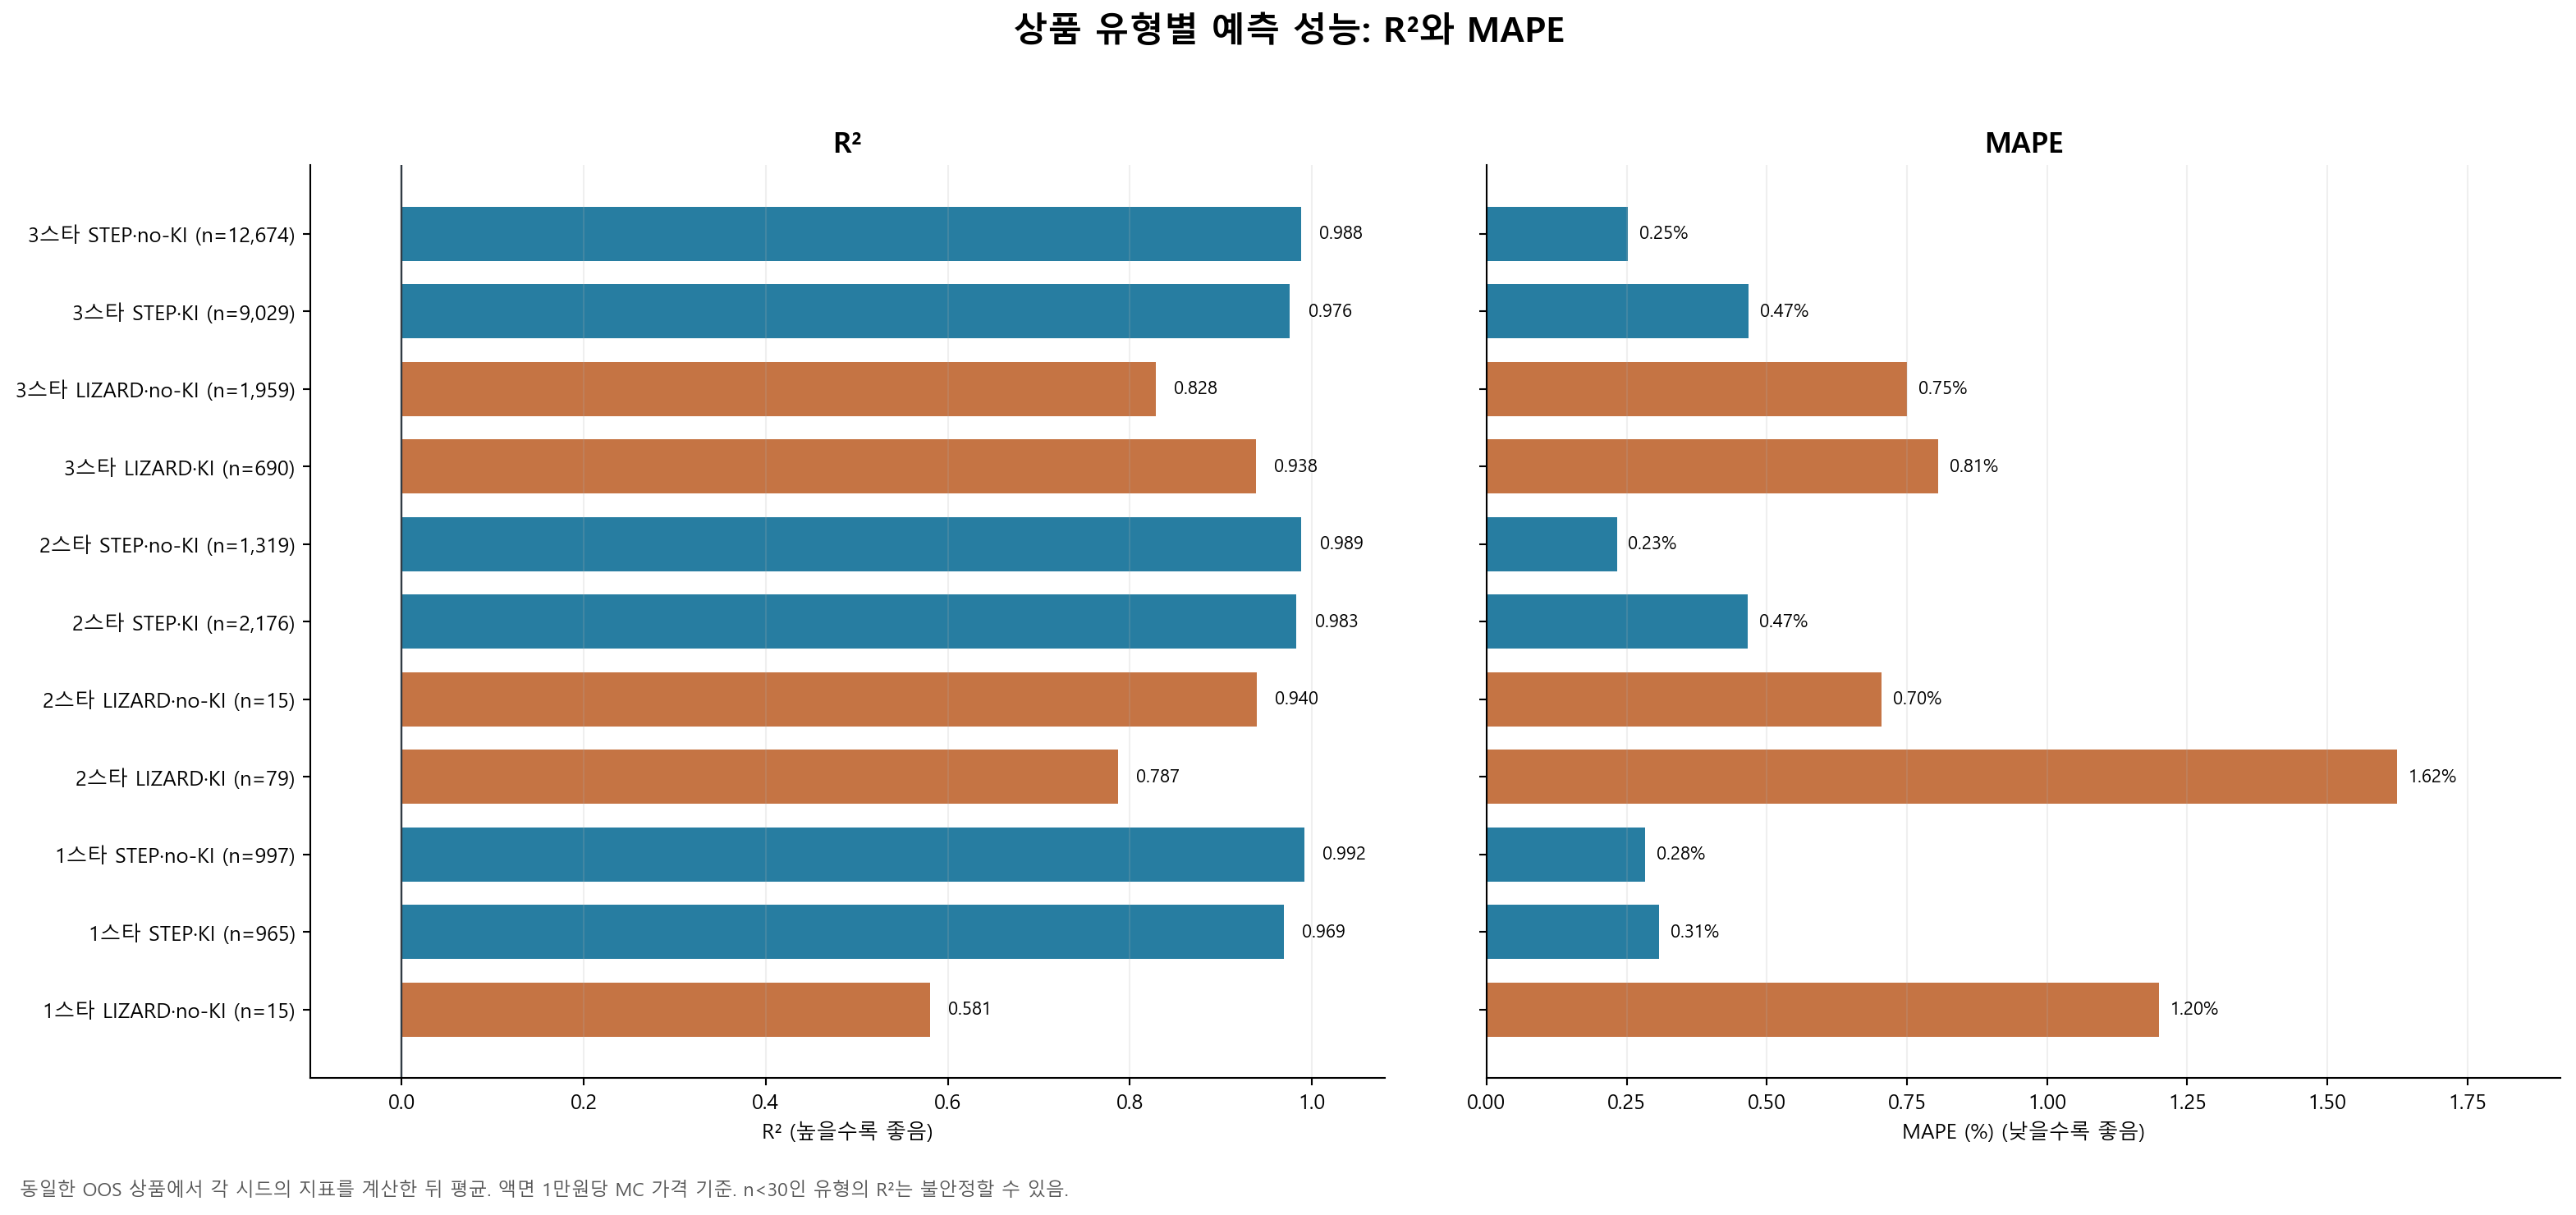

### Final_02_product_type_error_bands.png

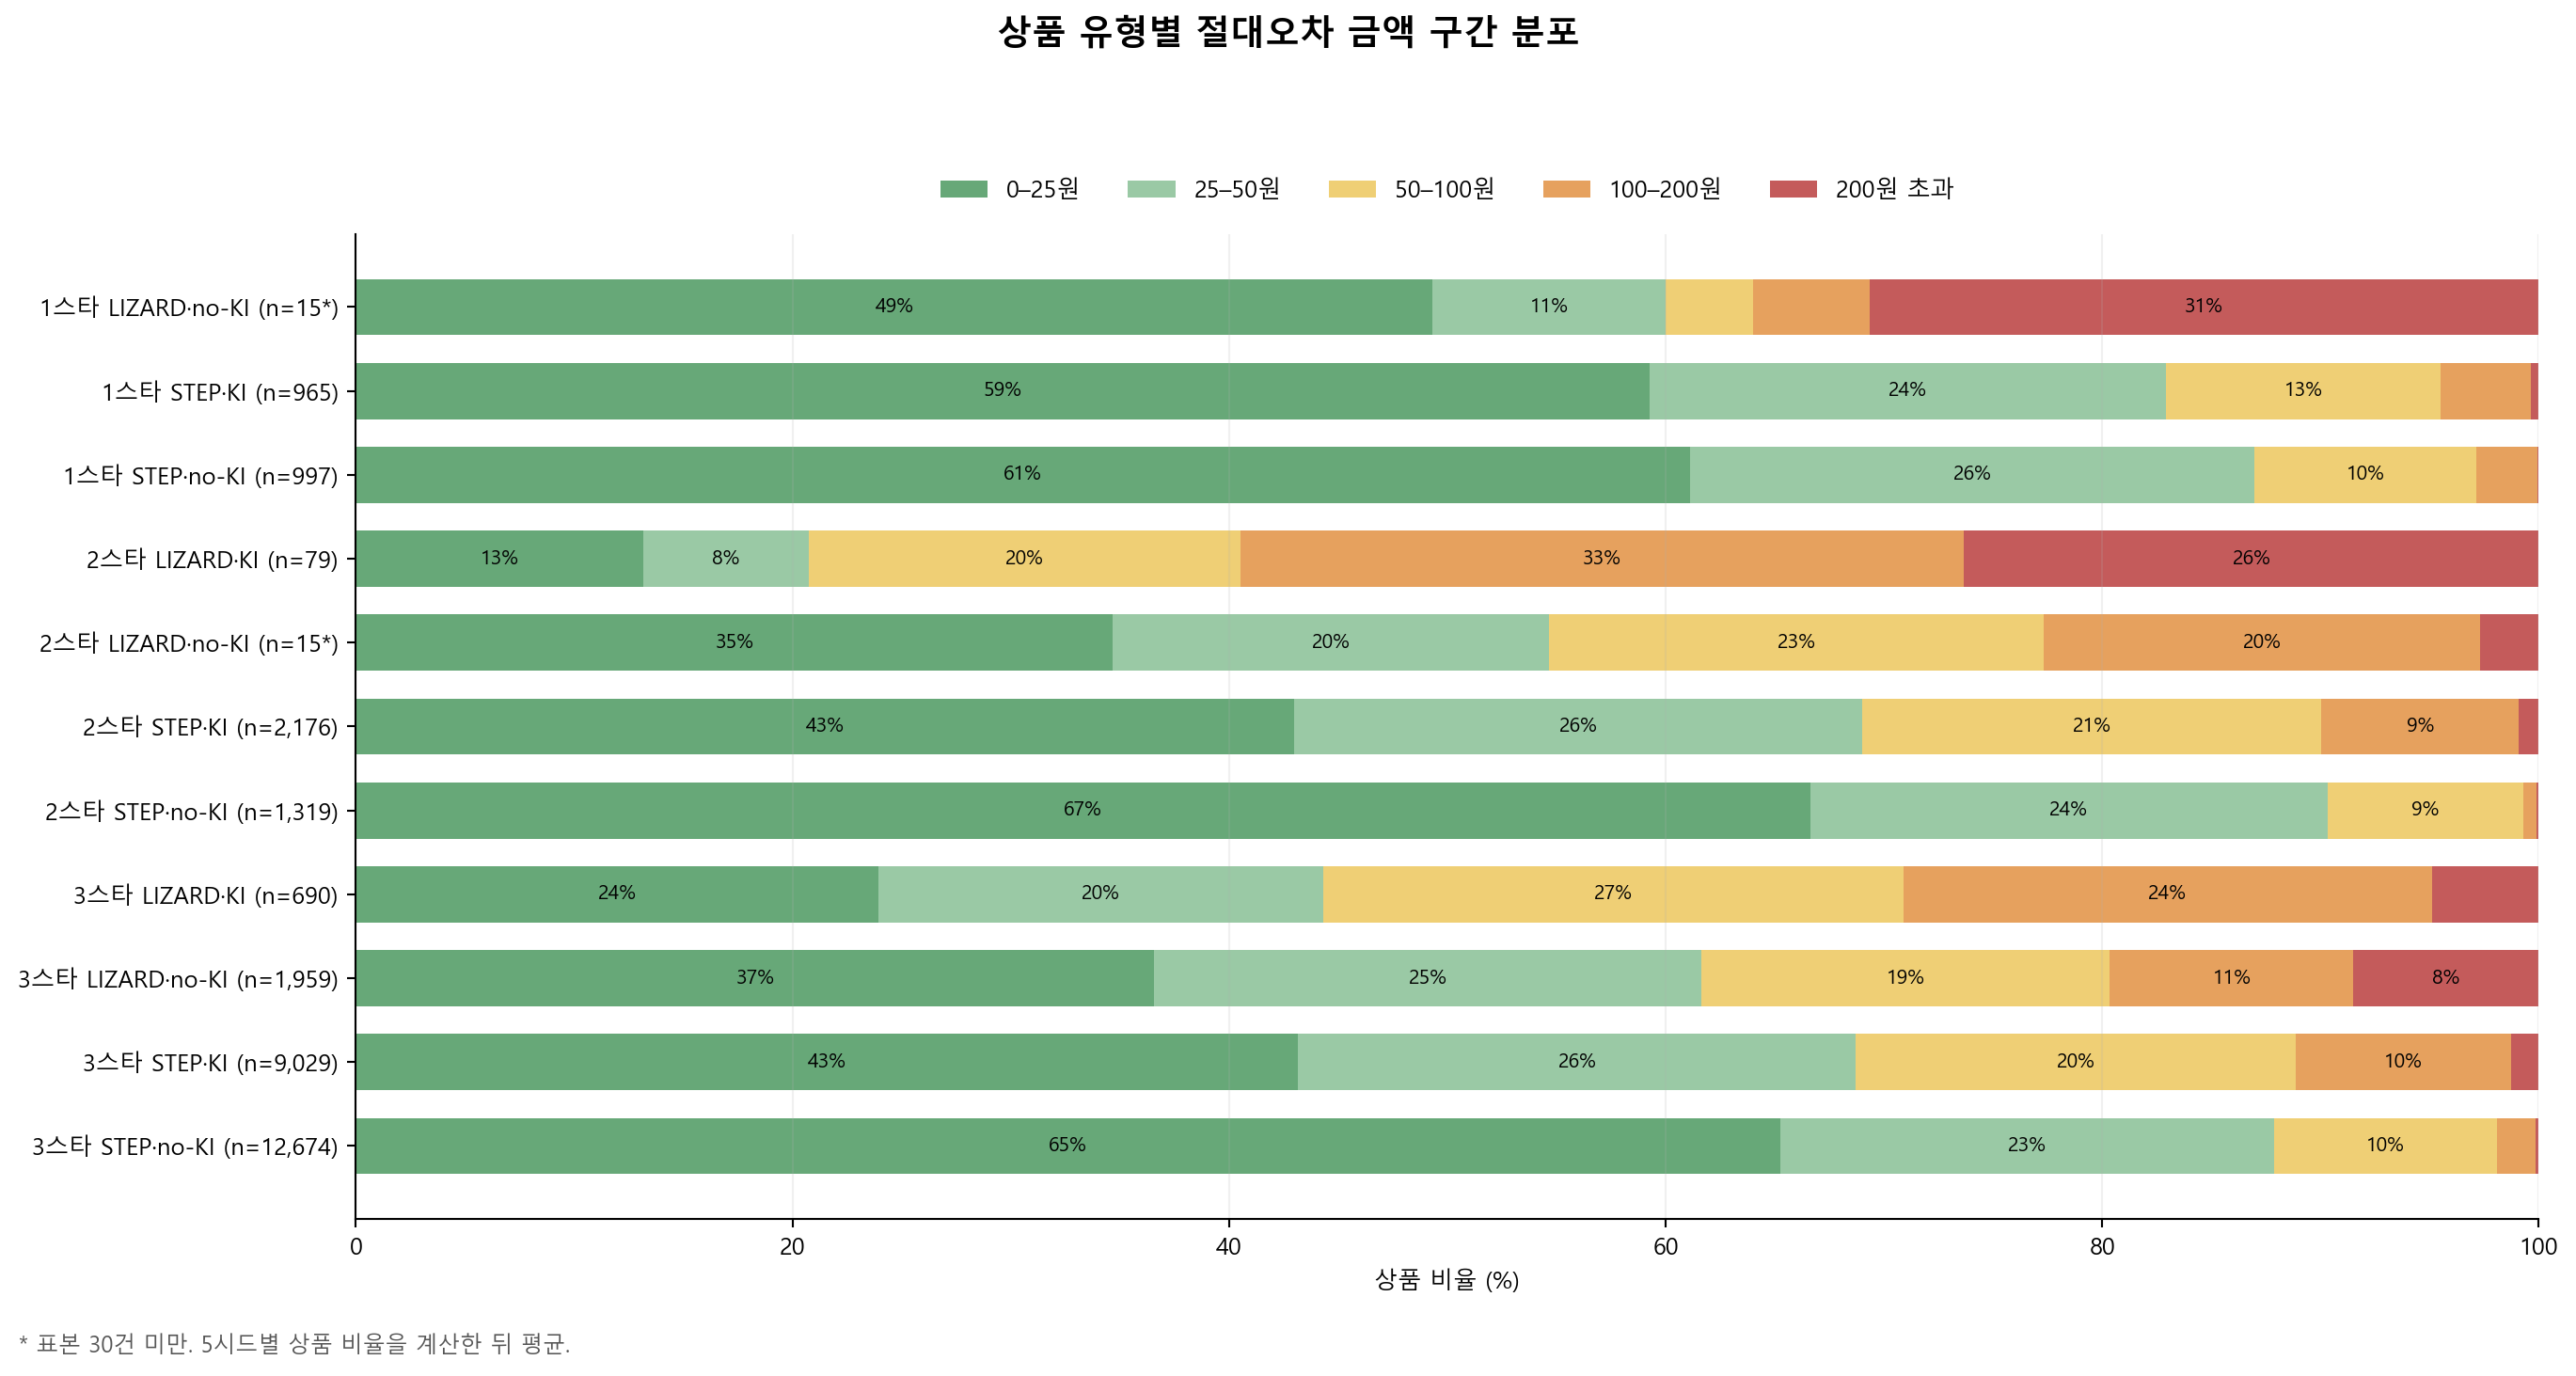

### Final_04_five_model_error_cdf.png

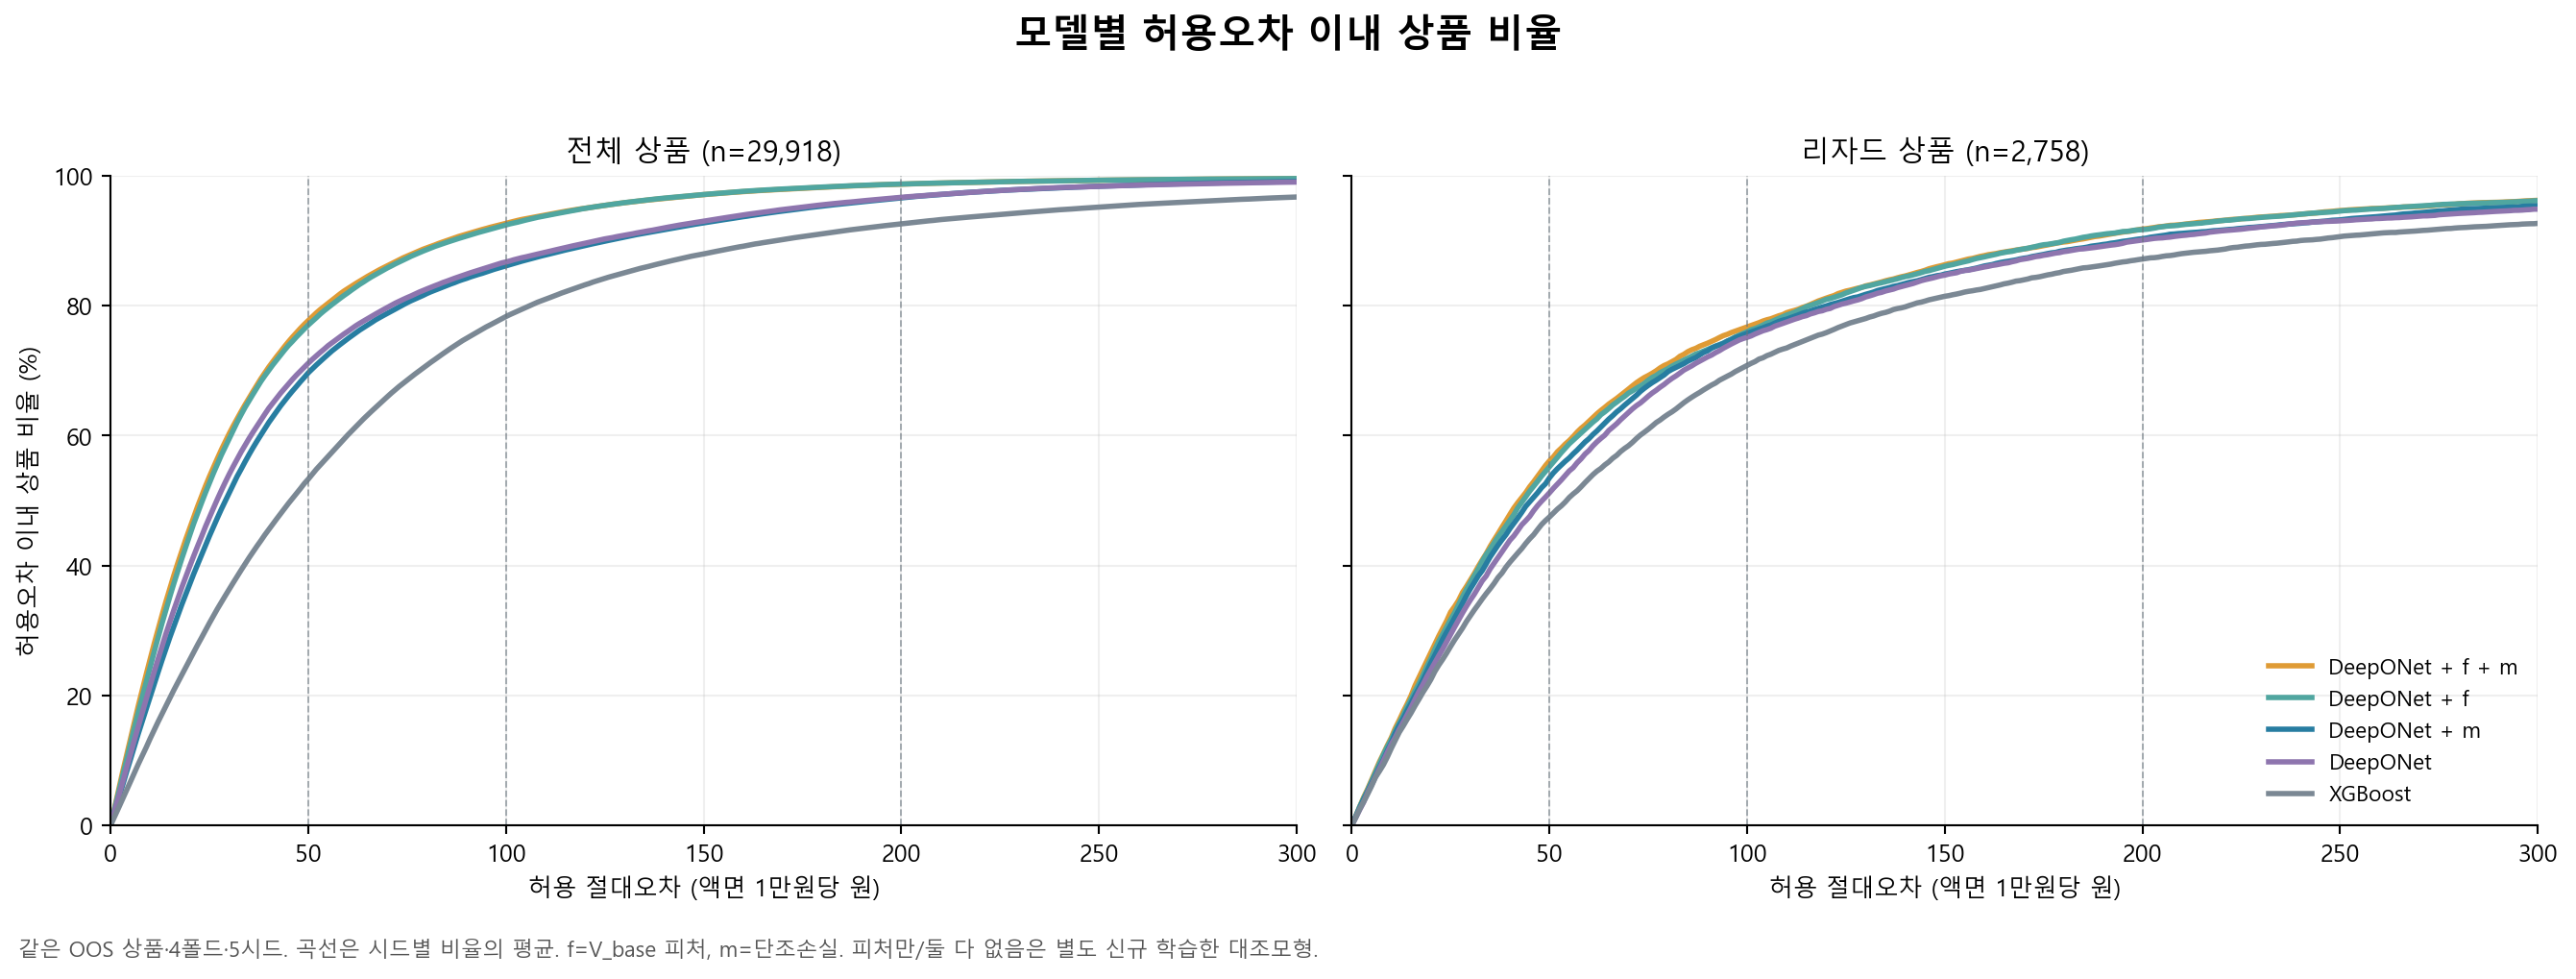

### Final_05_product_type_100krw_error_rate.png

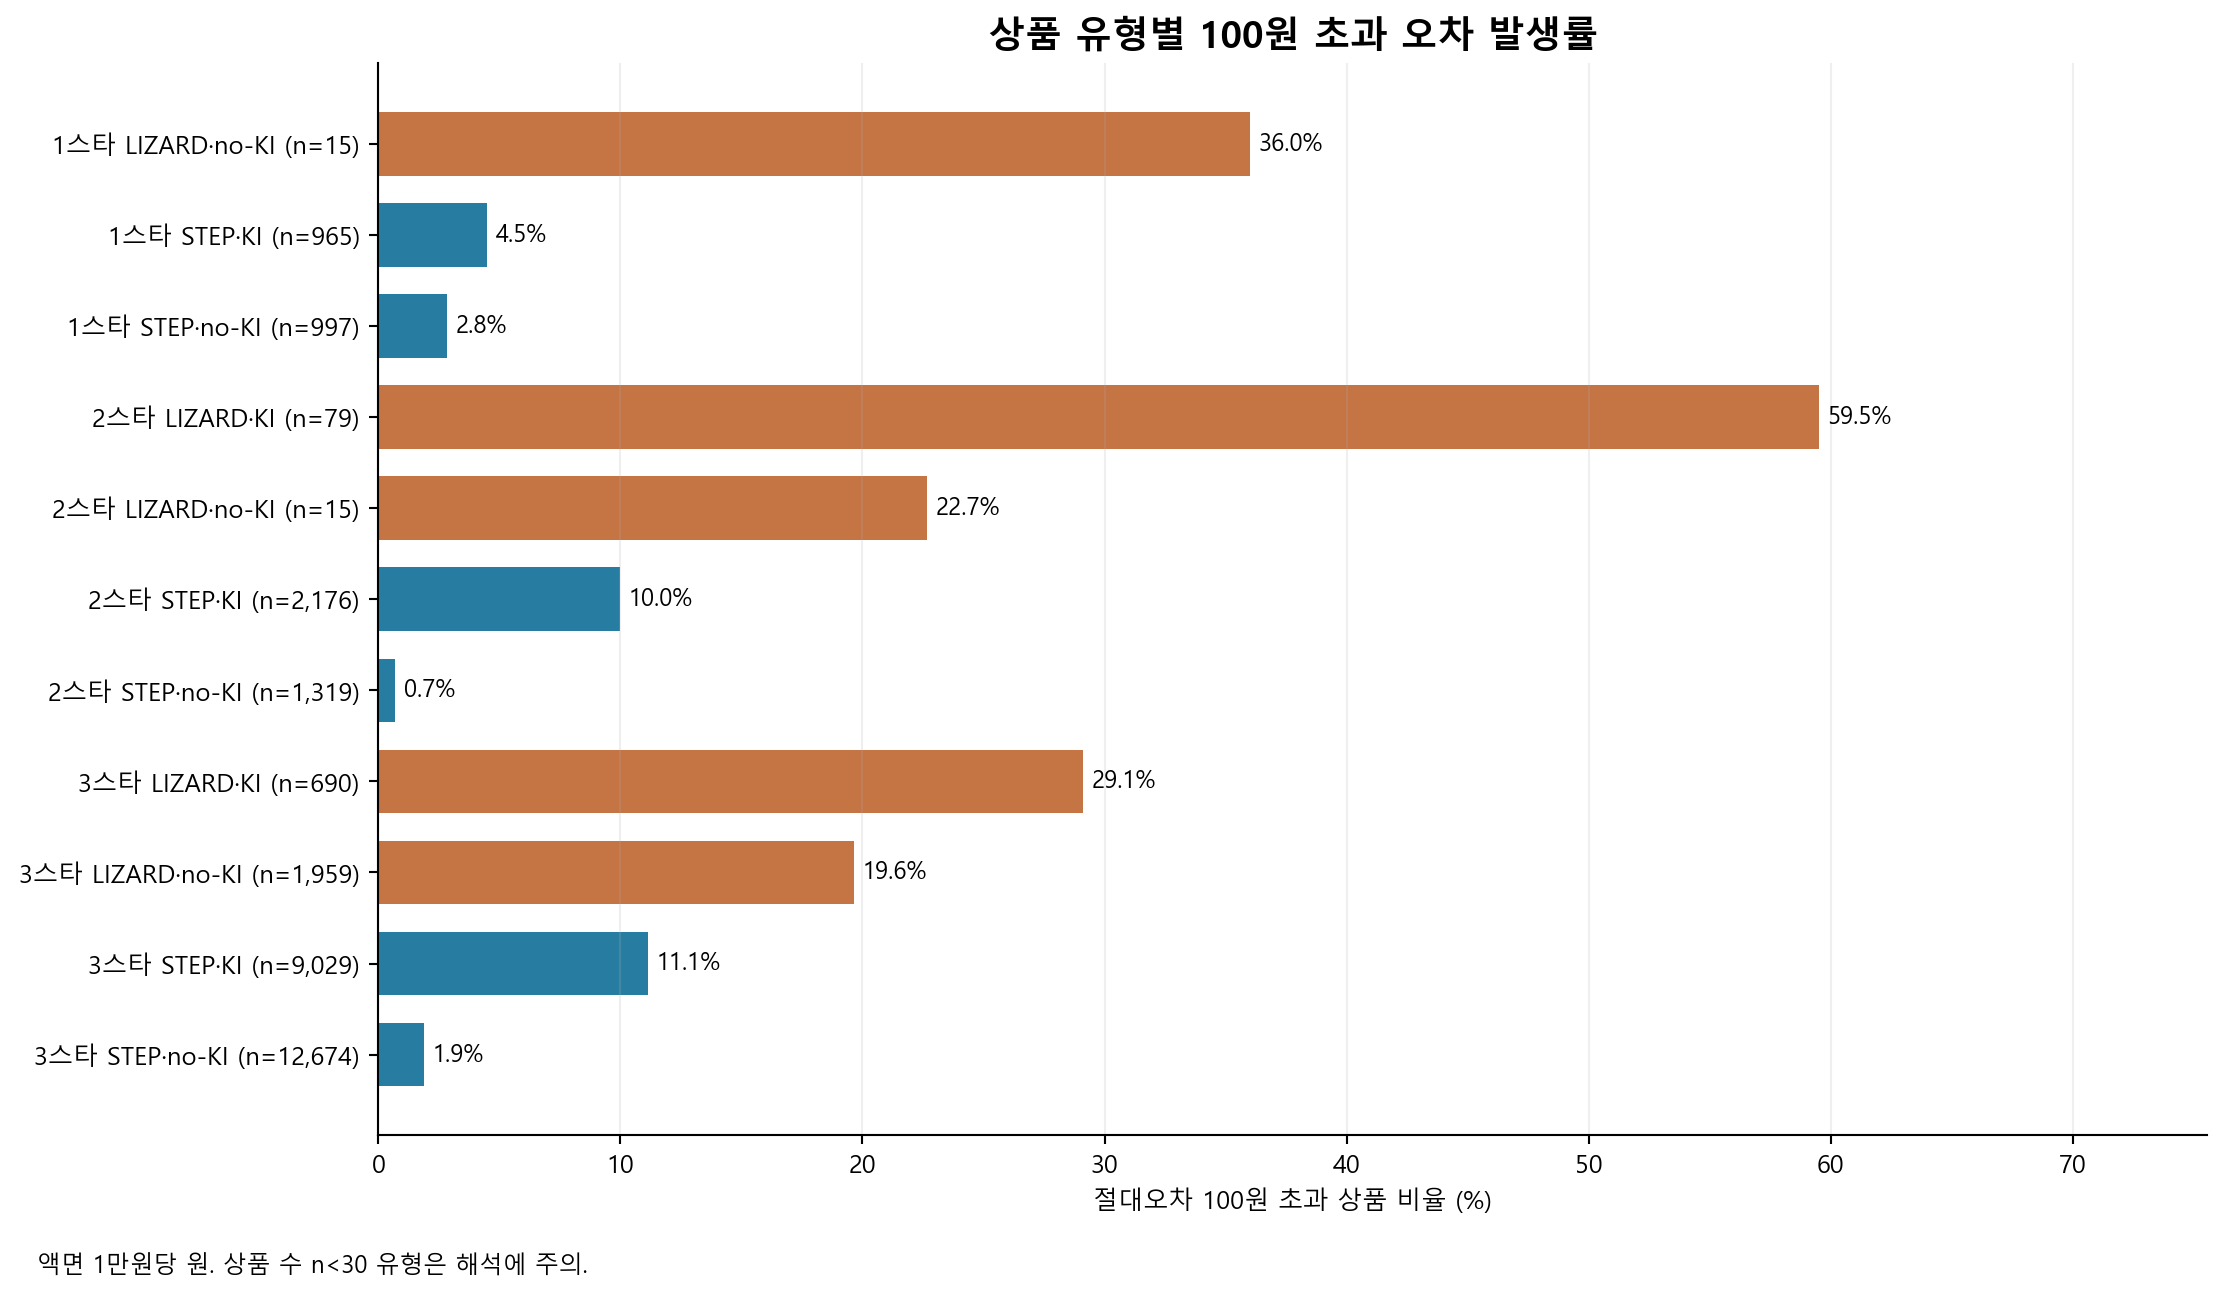

### Final_06_contract_and_MC_price_MAPE.png

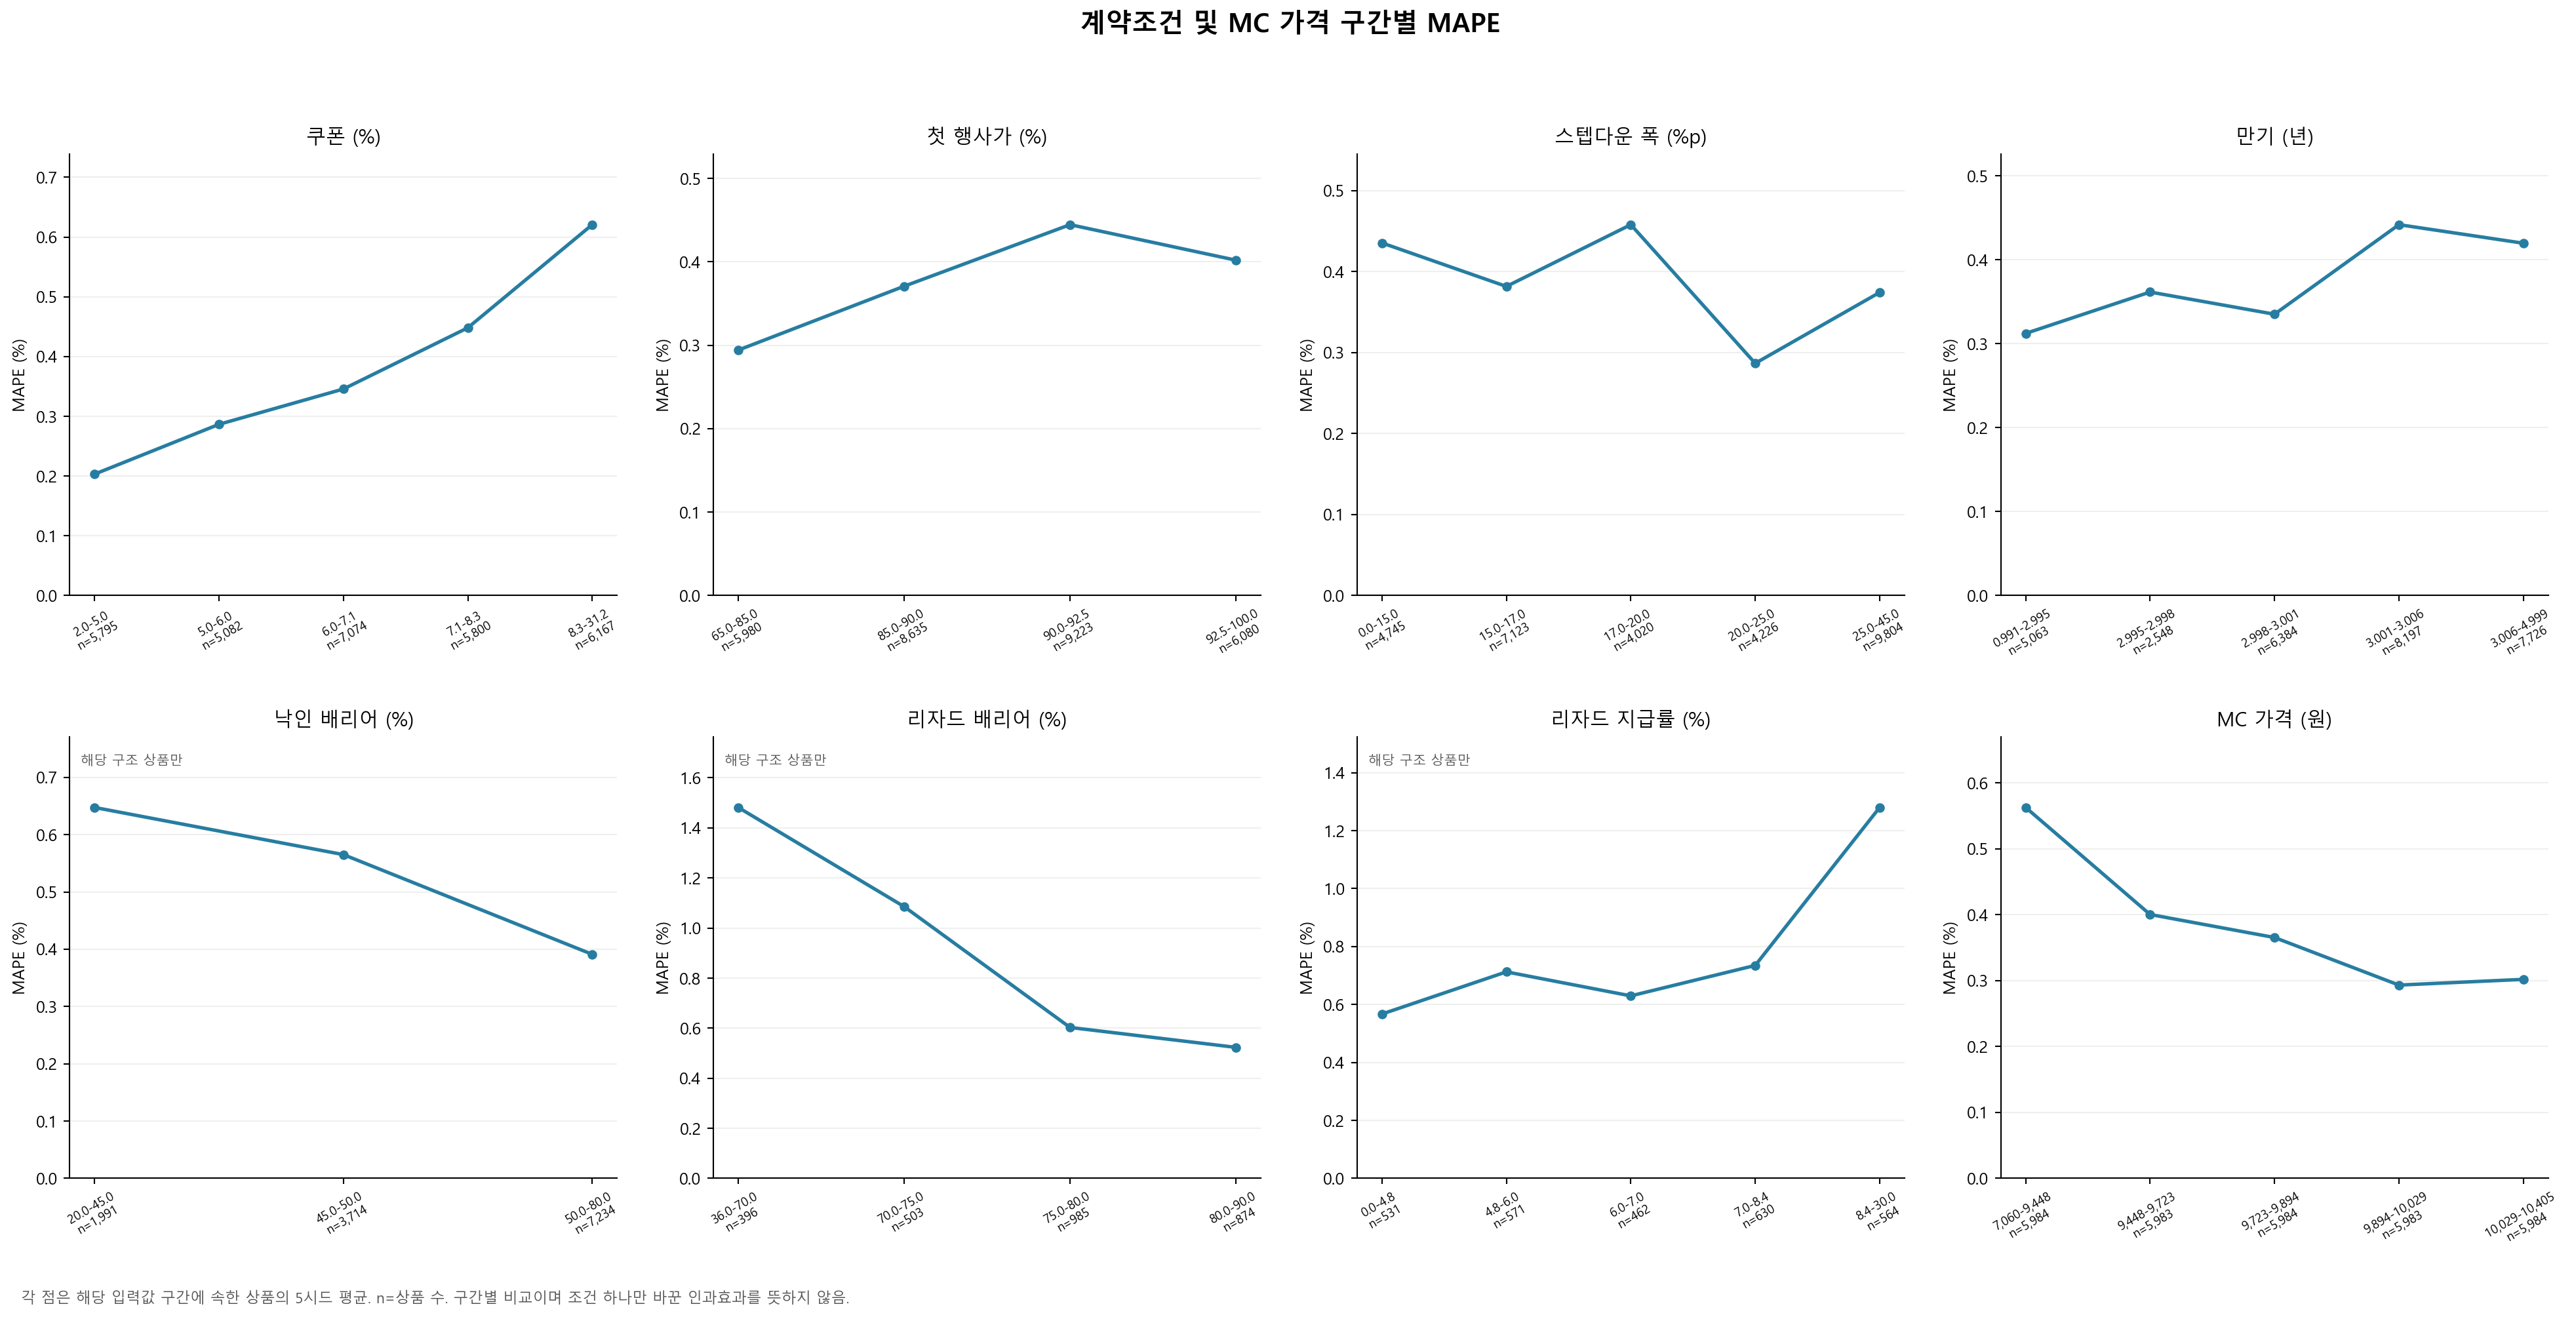

### Final_07_contract_and_market_MAE.png

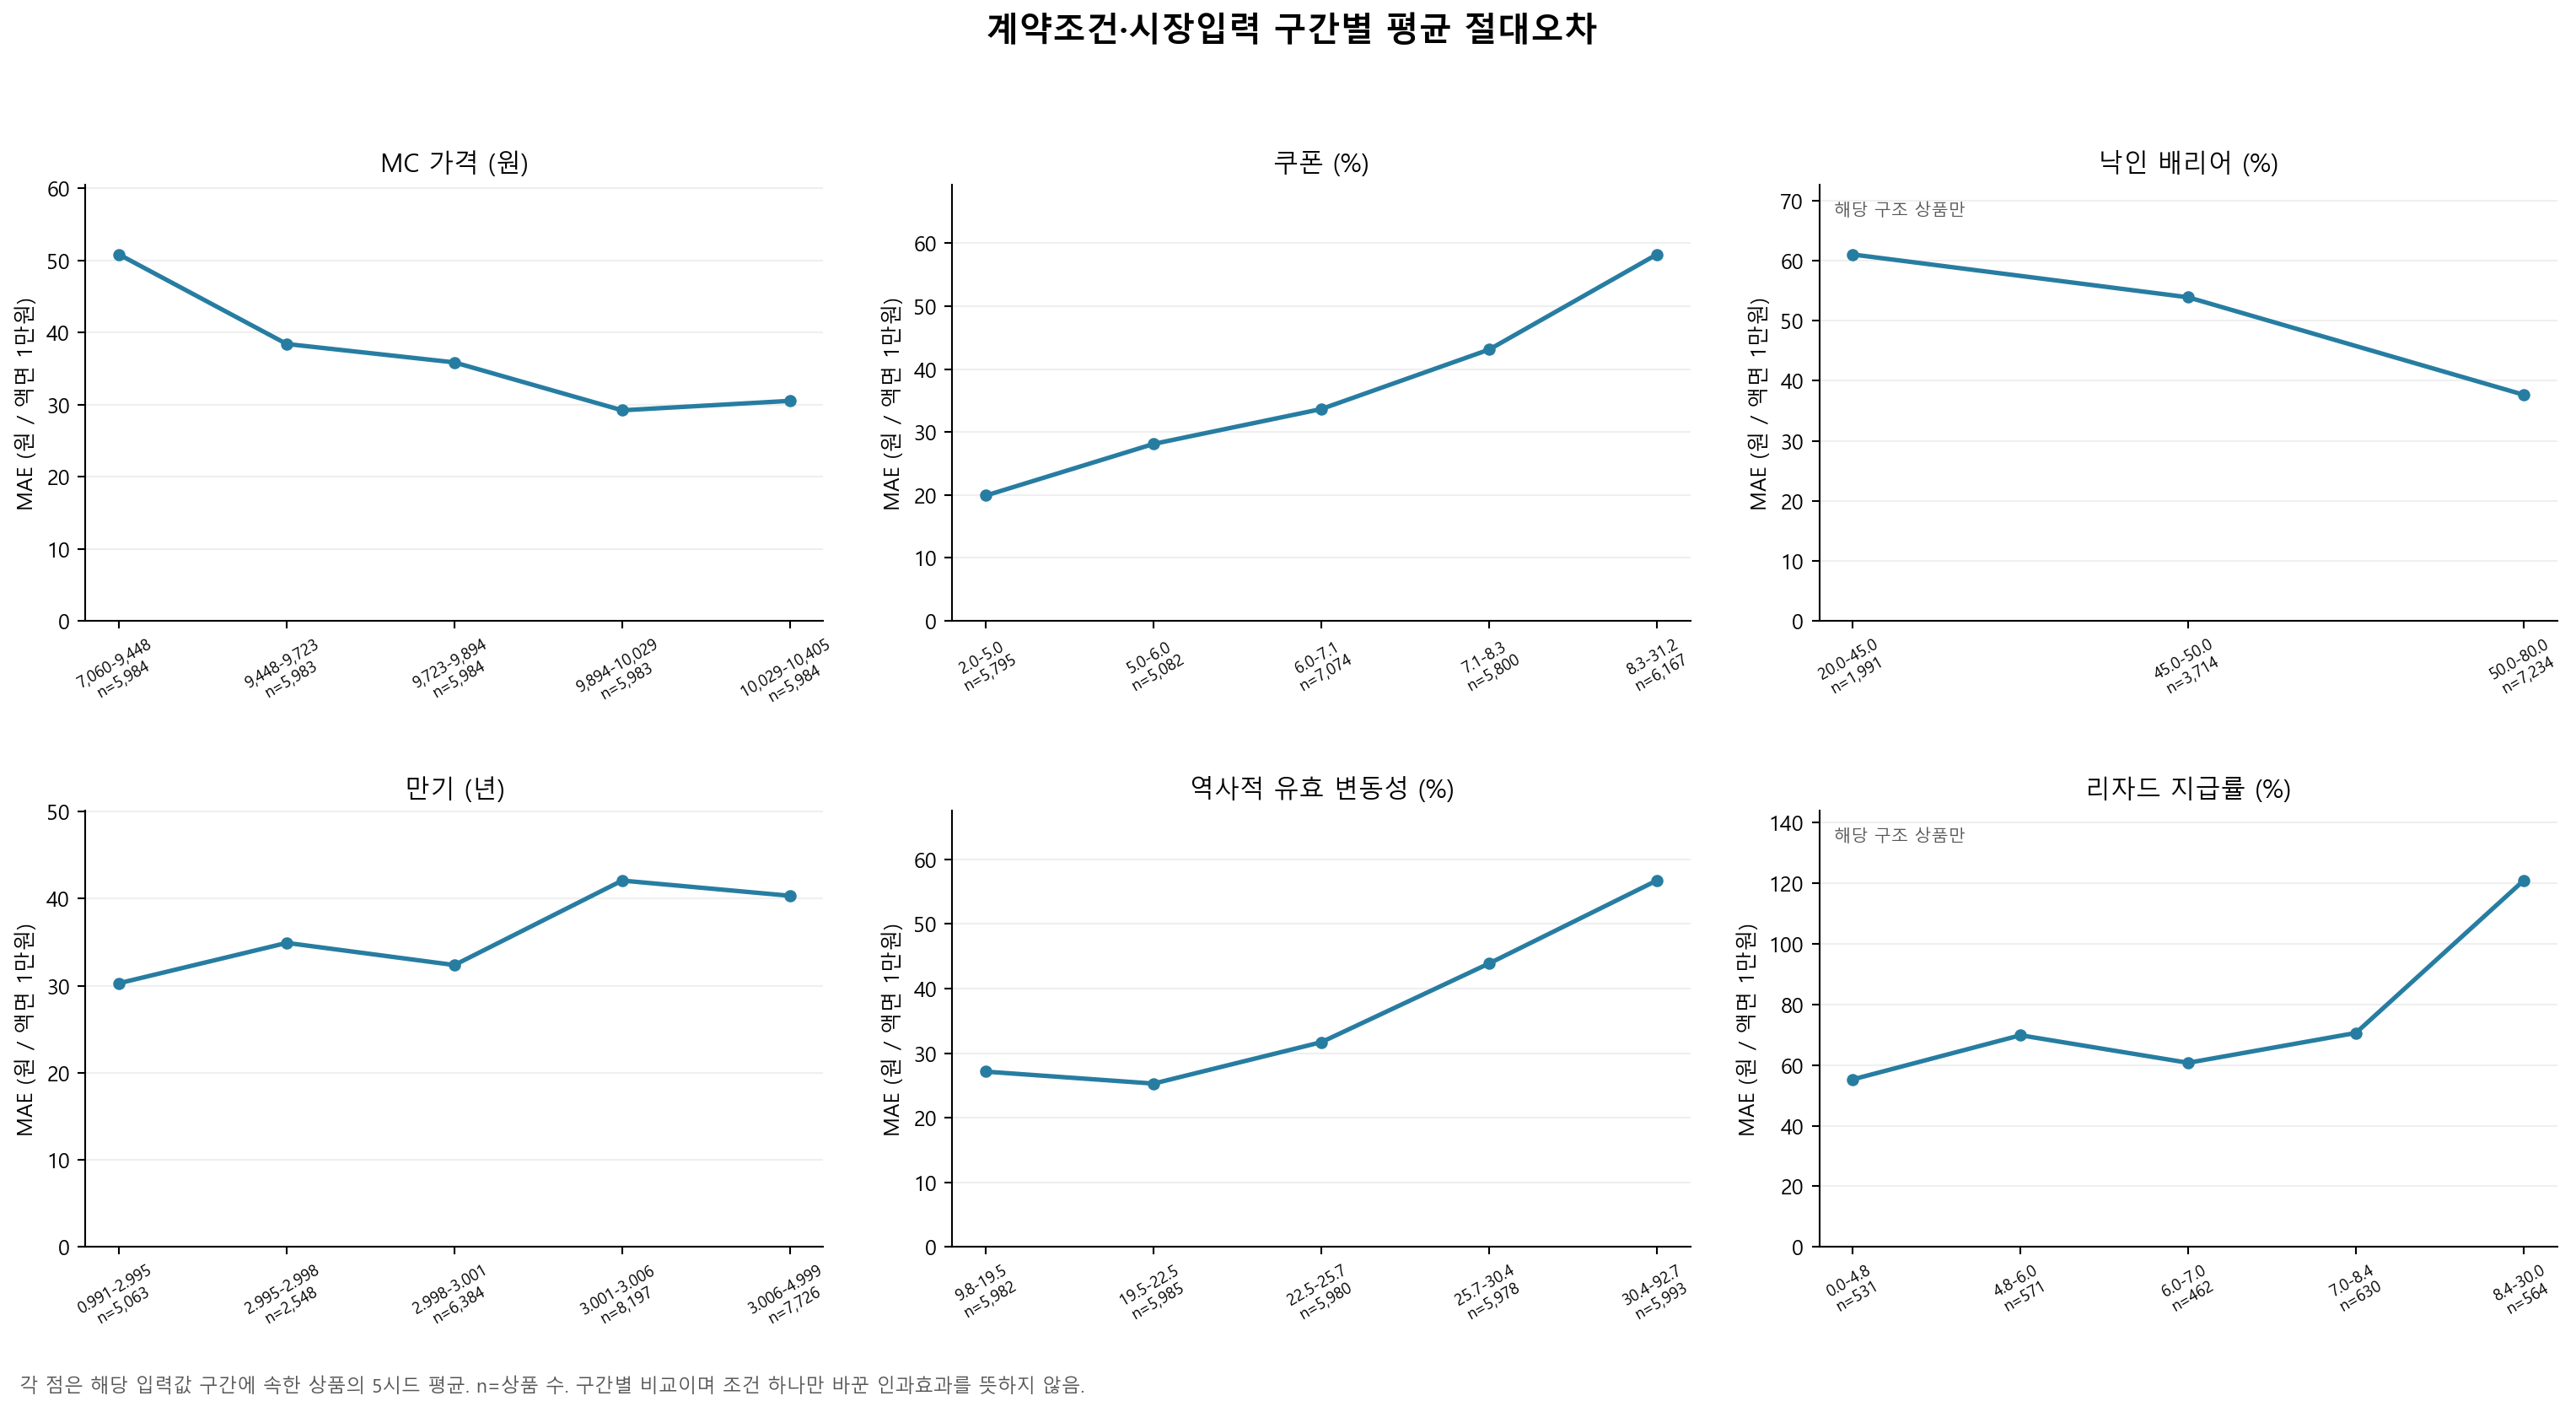

### Final_12_MC_price_MAPE_distribution.png

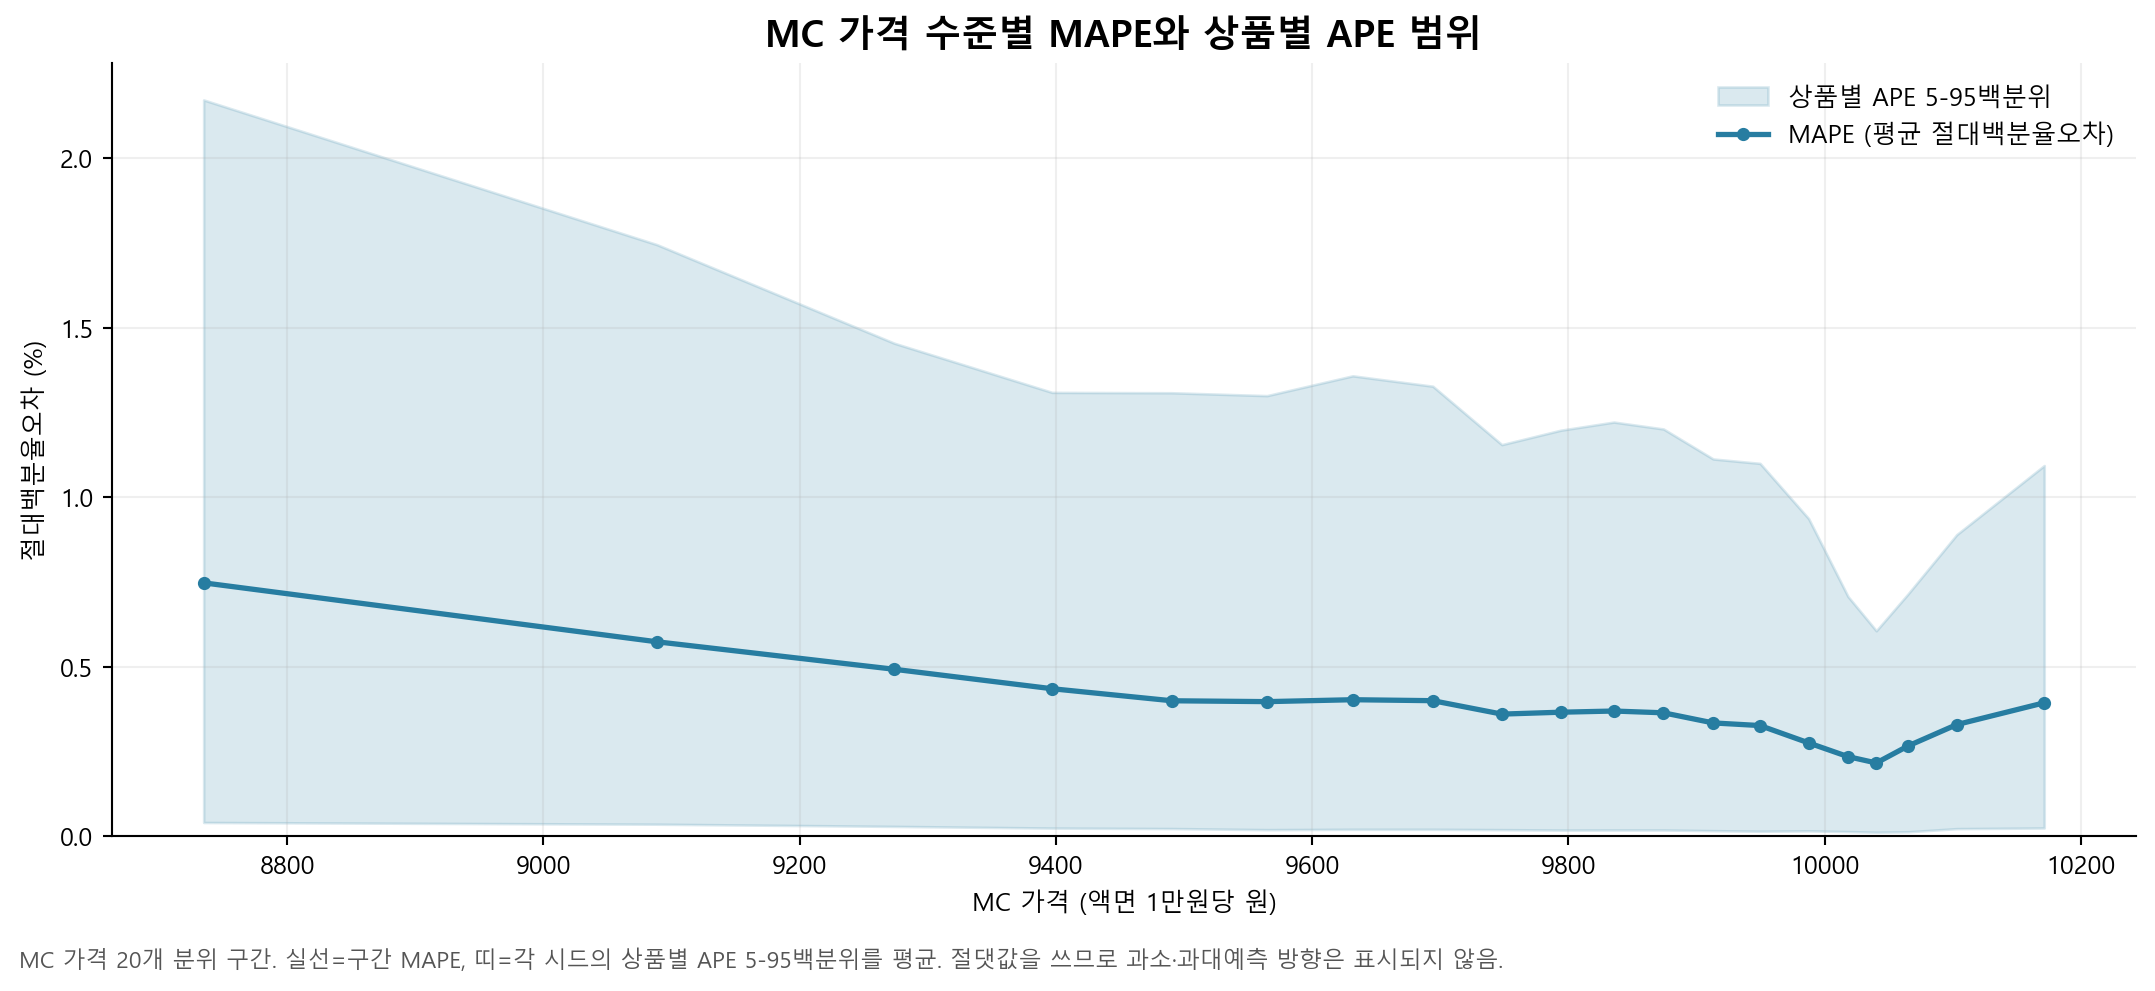

## 현재 로컬 결과 미리보기

### Final_32_product_type_signed_kde_subplots.png

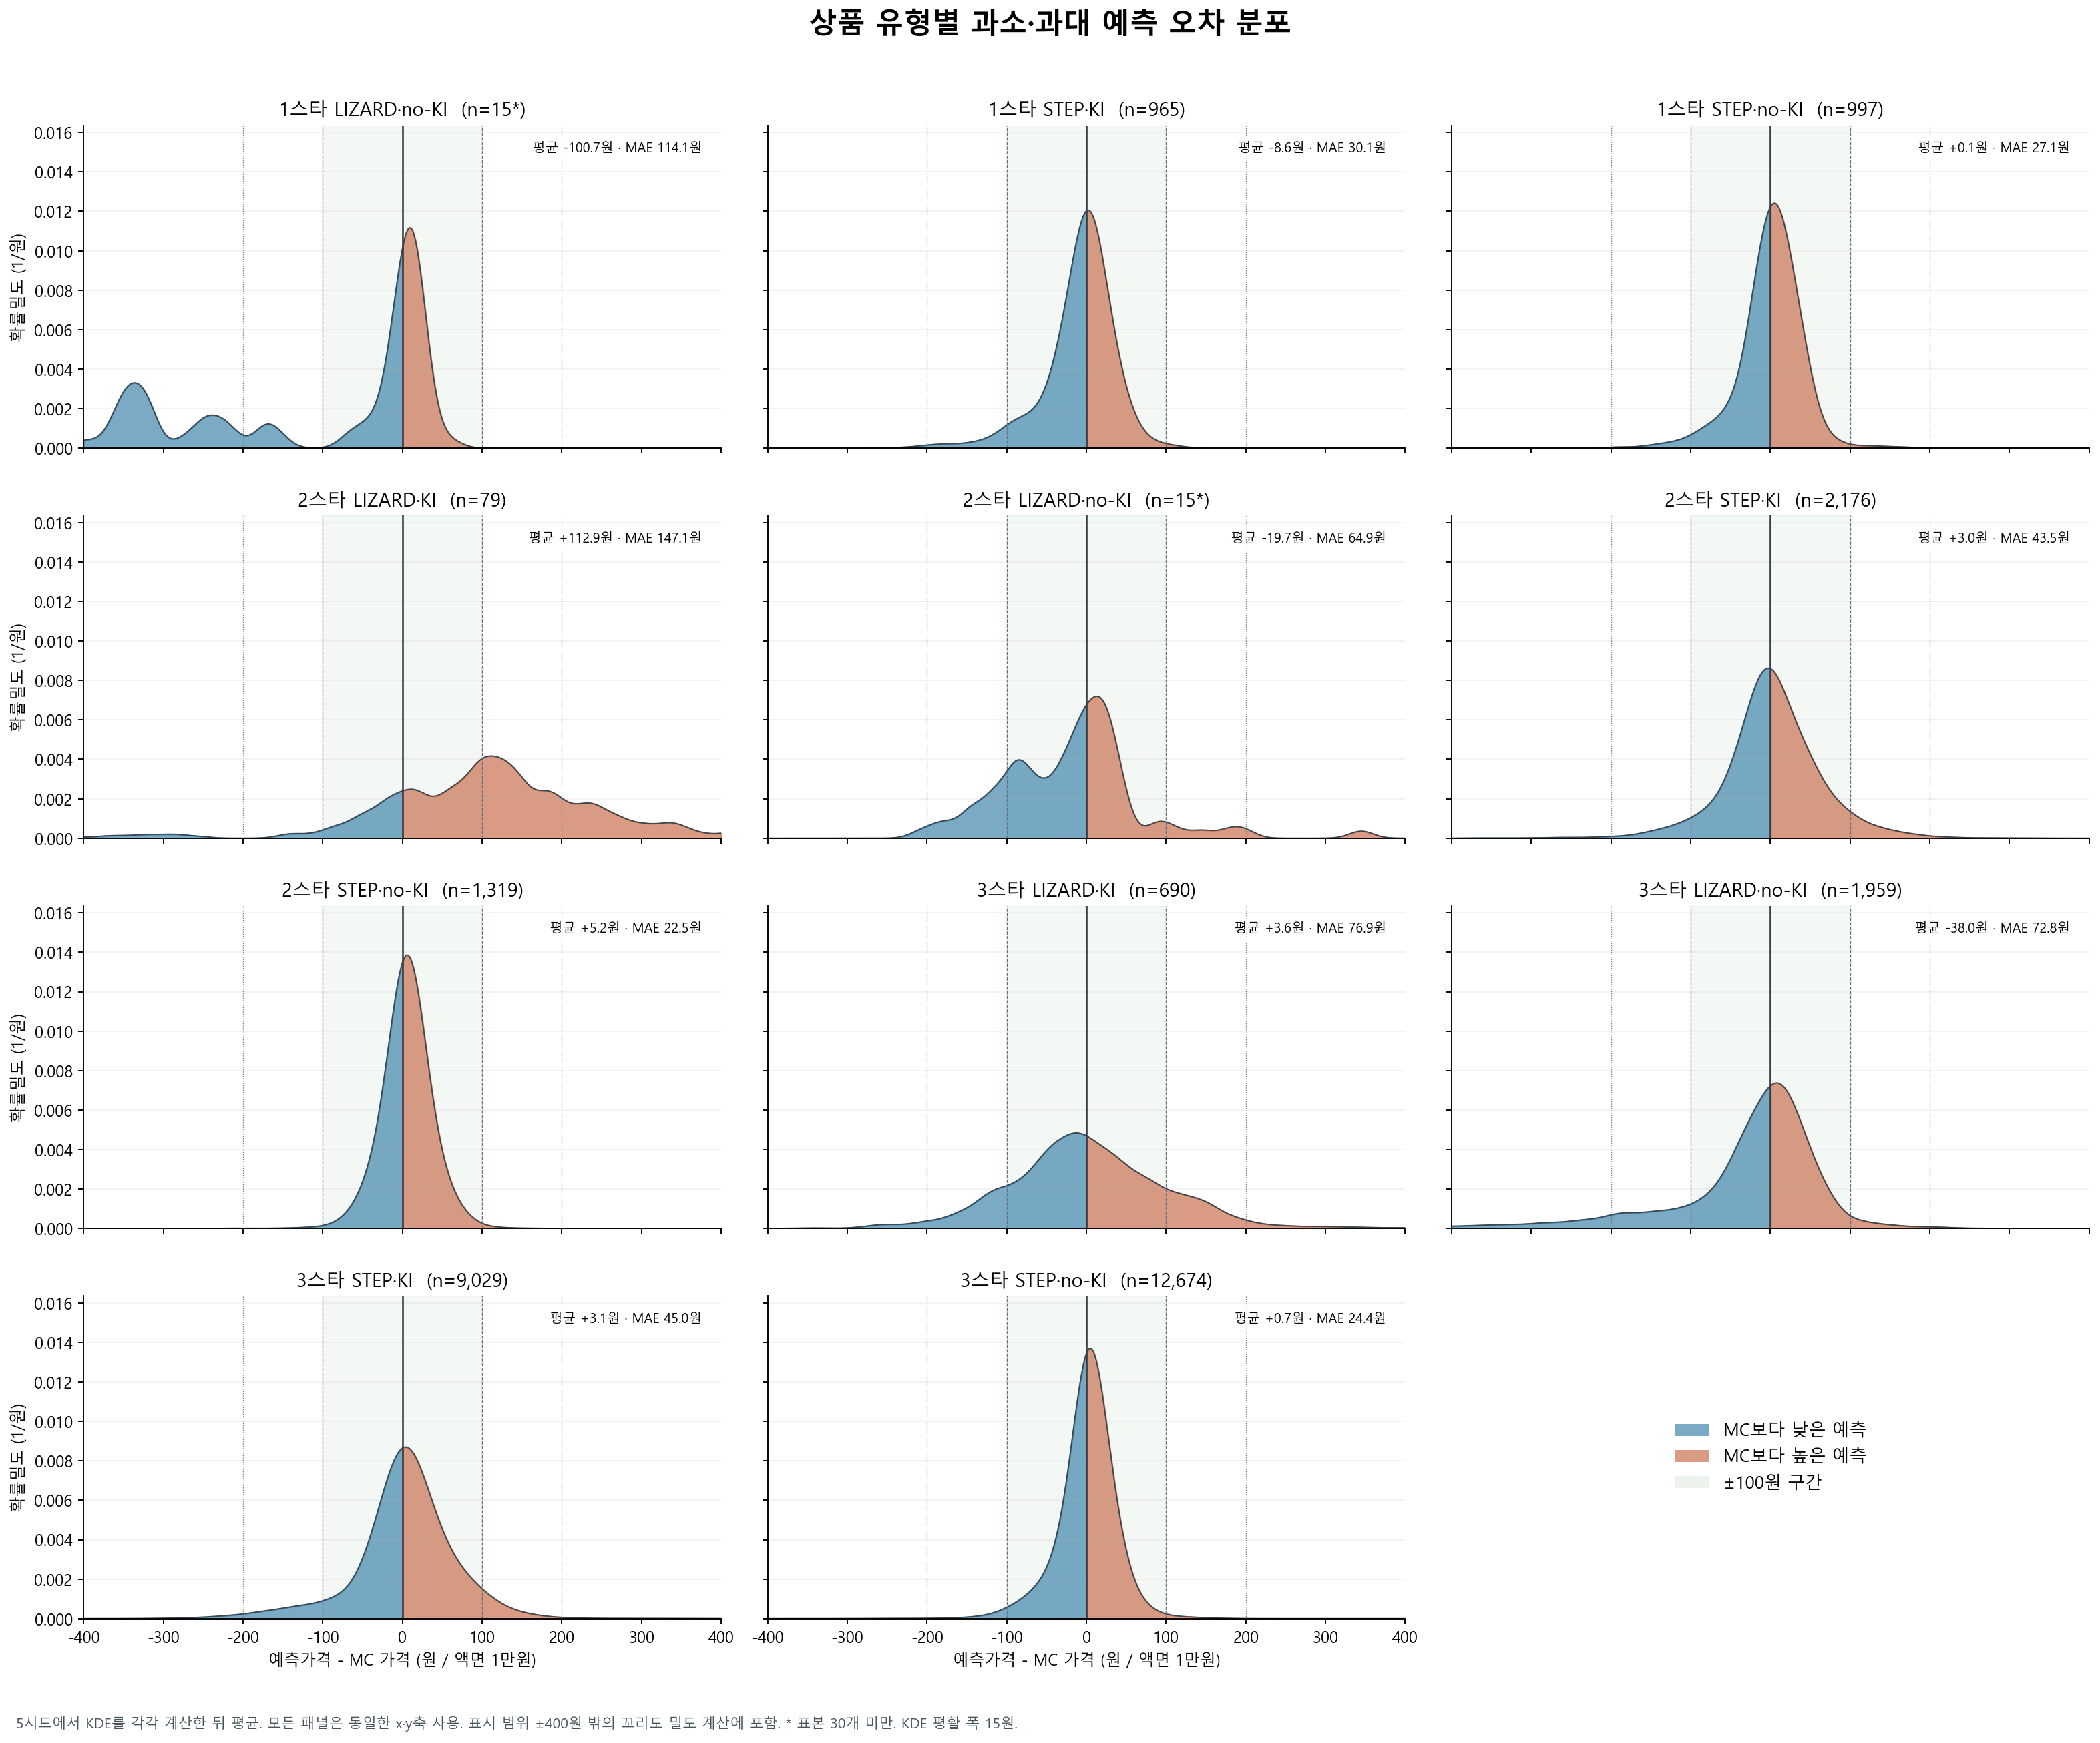

### Final_35_five_model_MC_vs_prediction_subplots.png

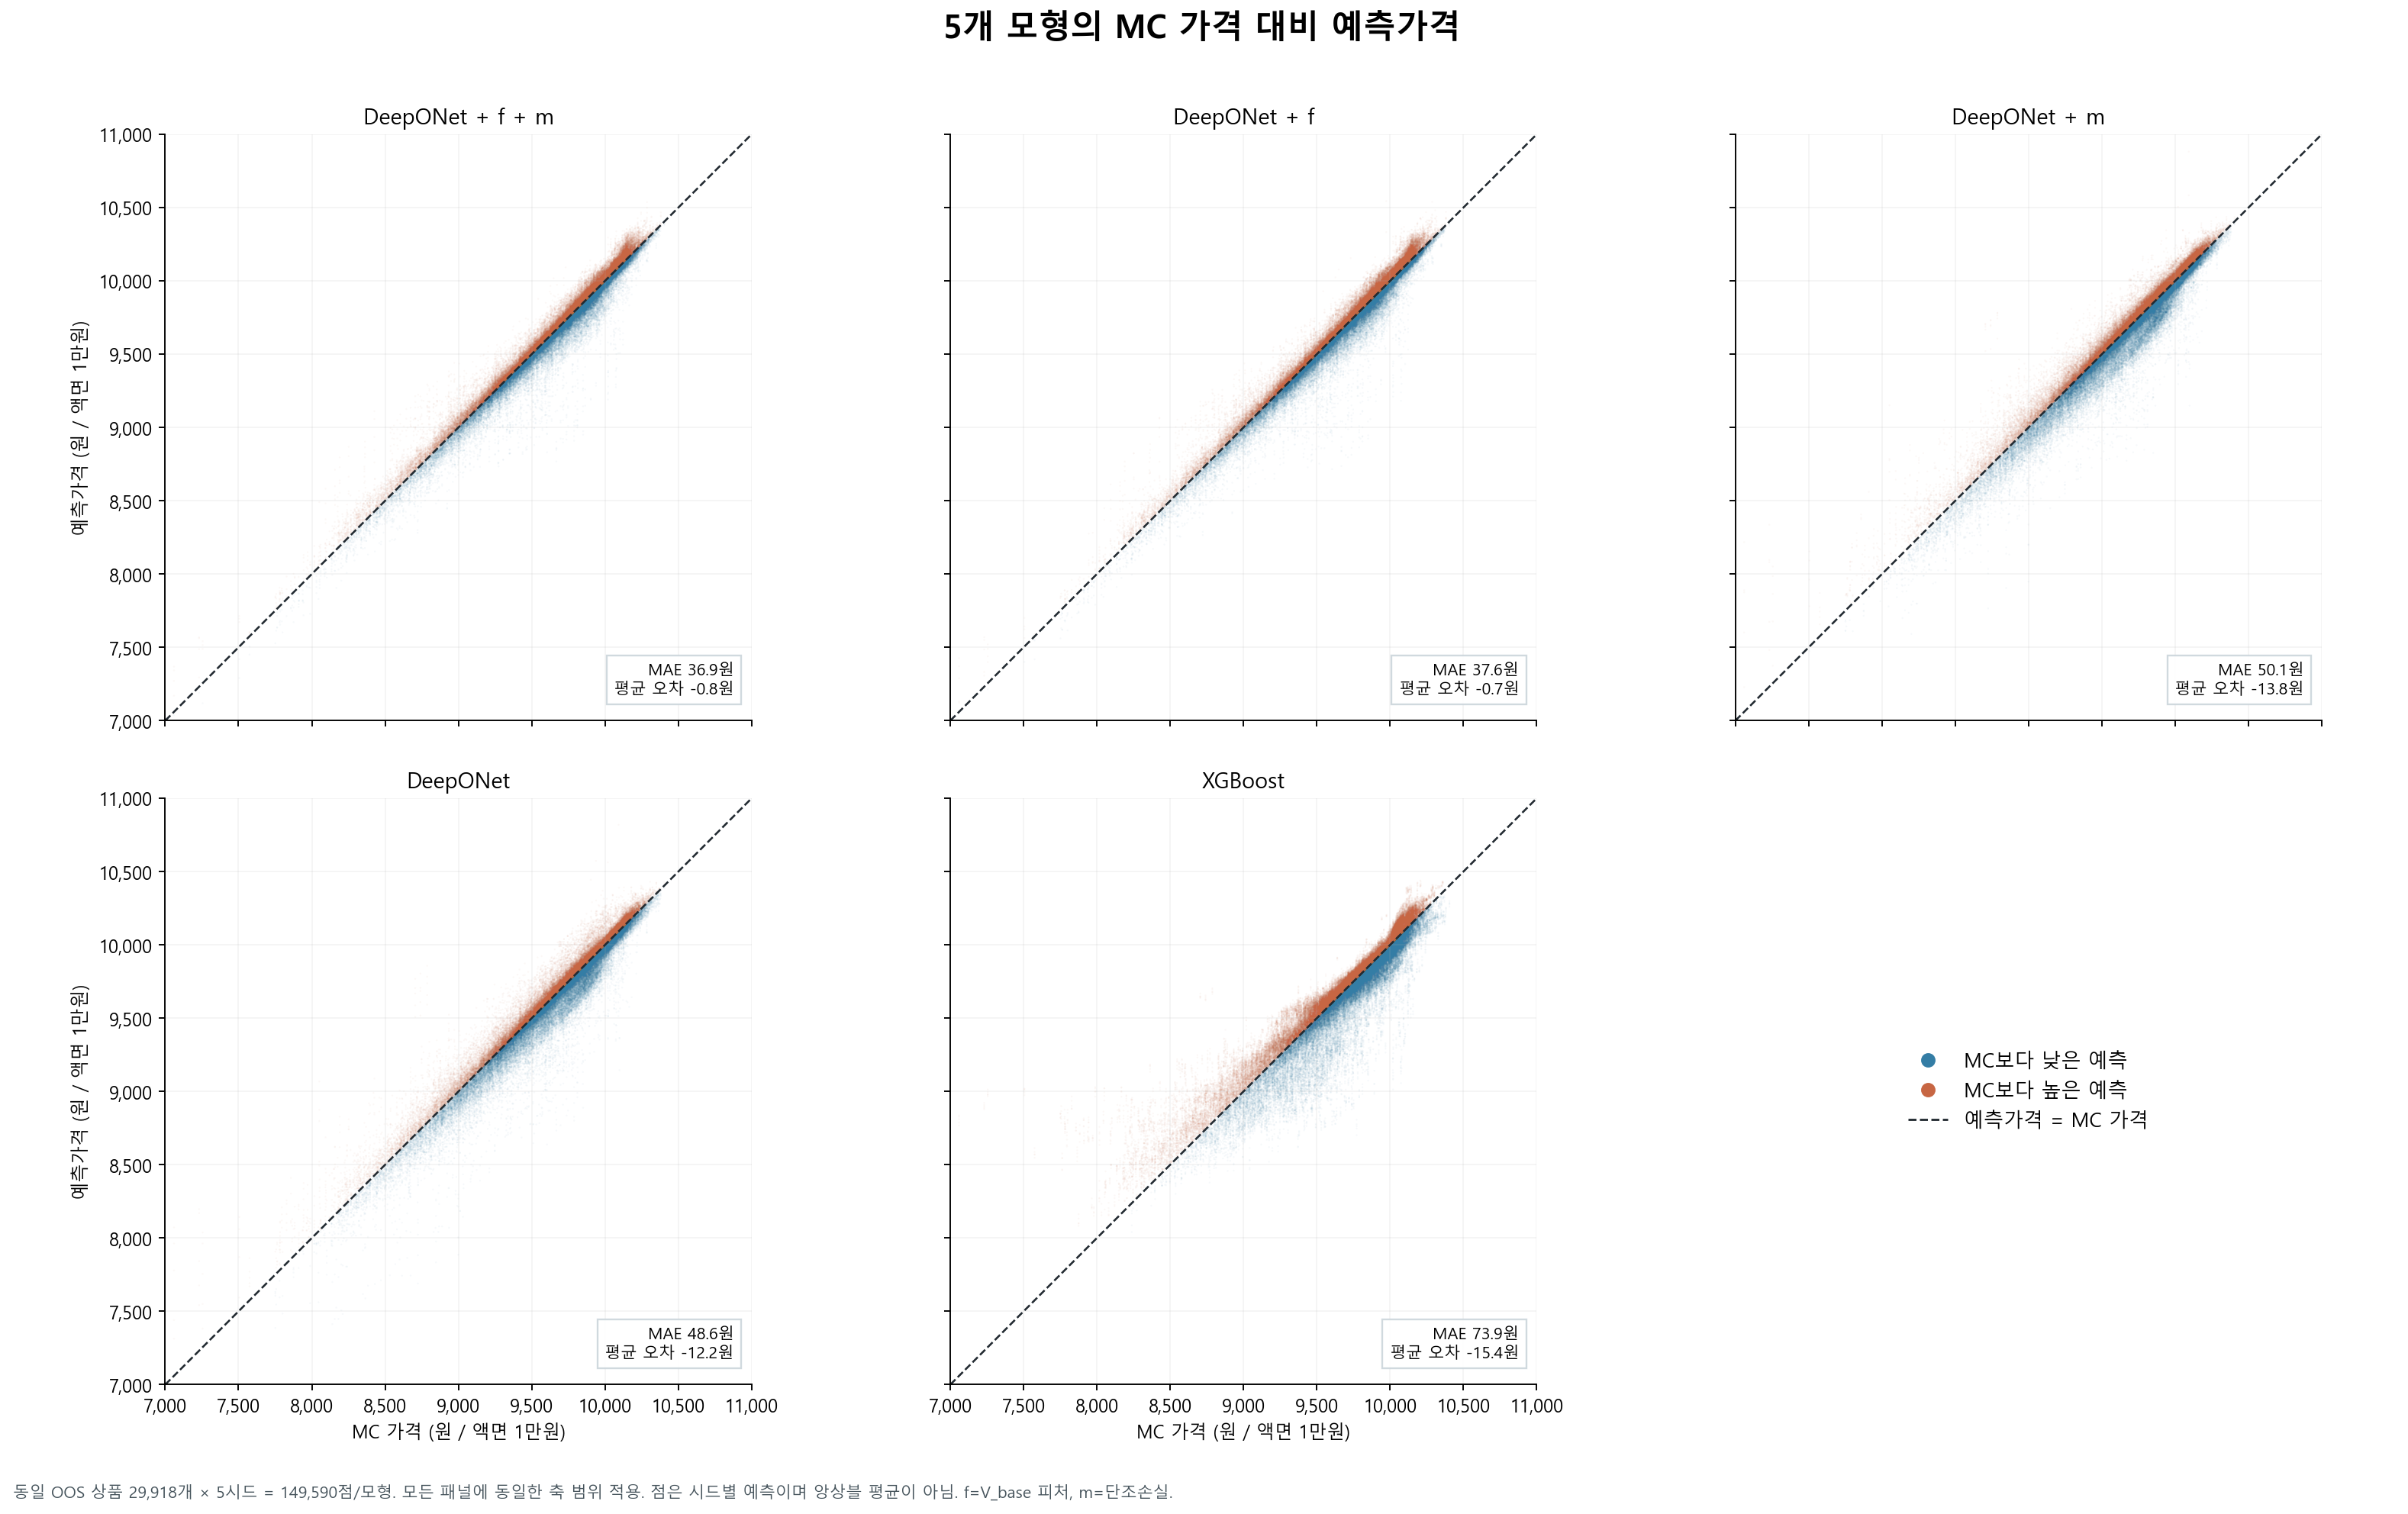

### 16_underlying_asset_error_distribution.png

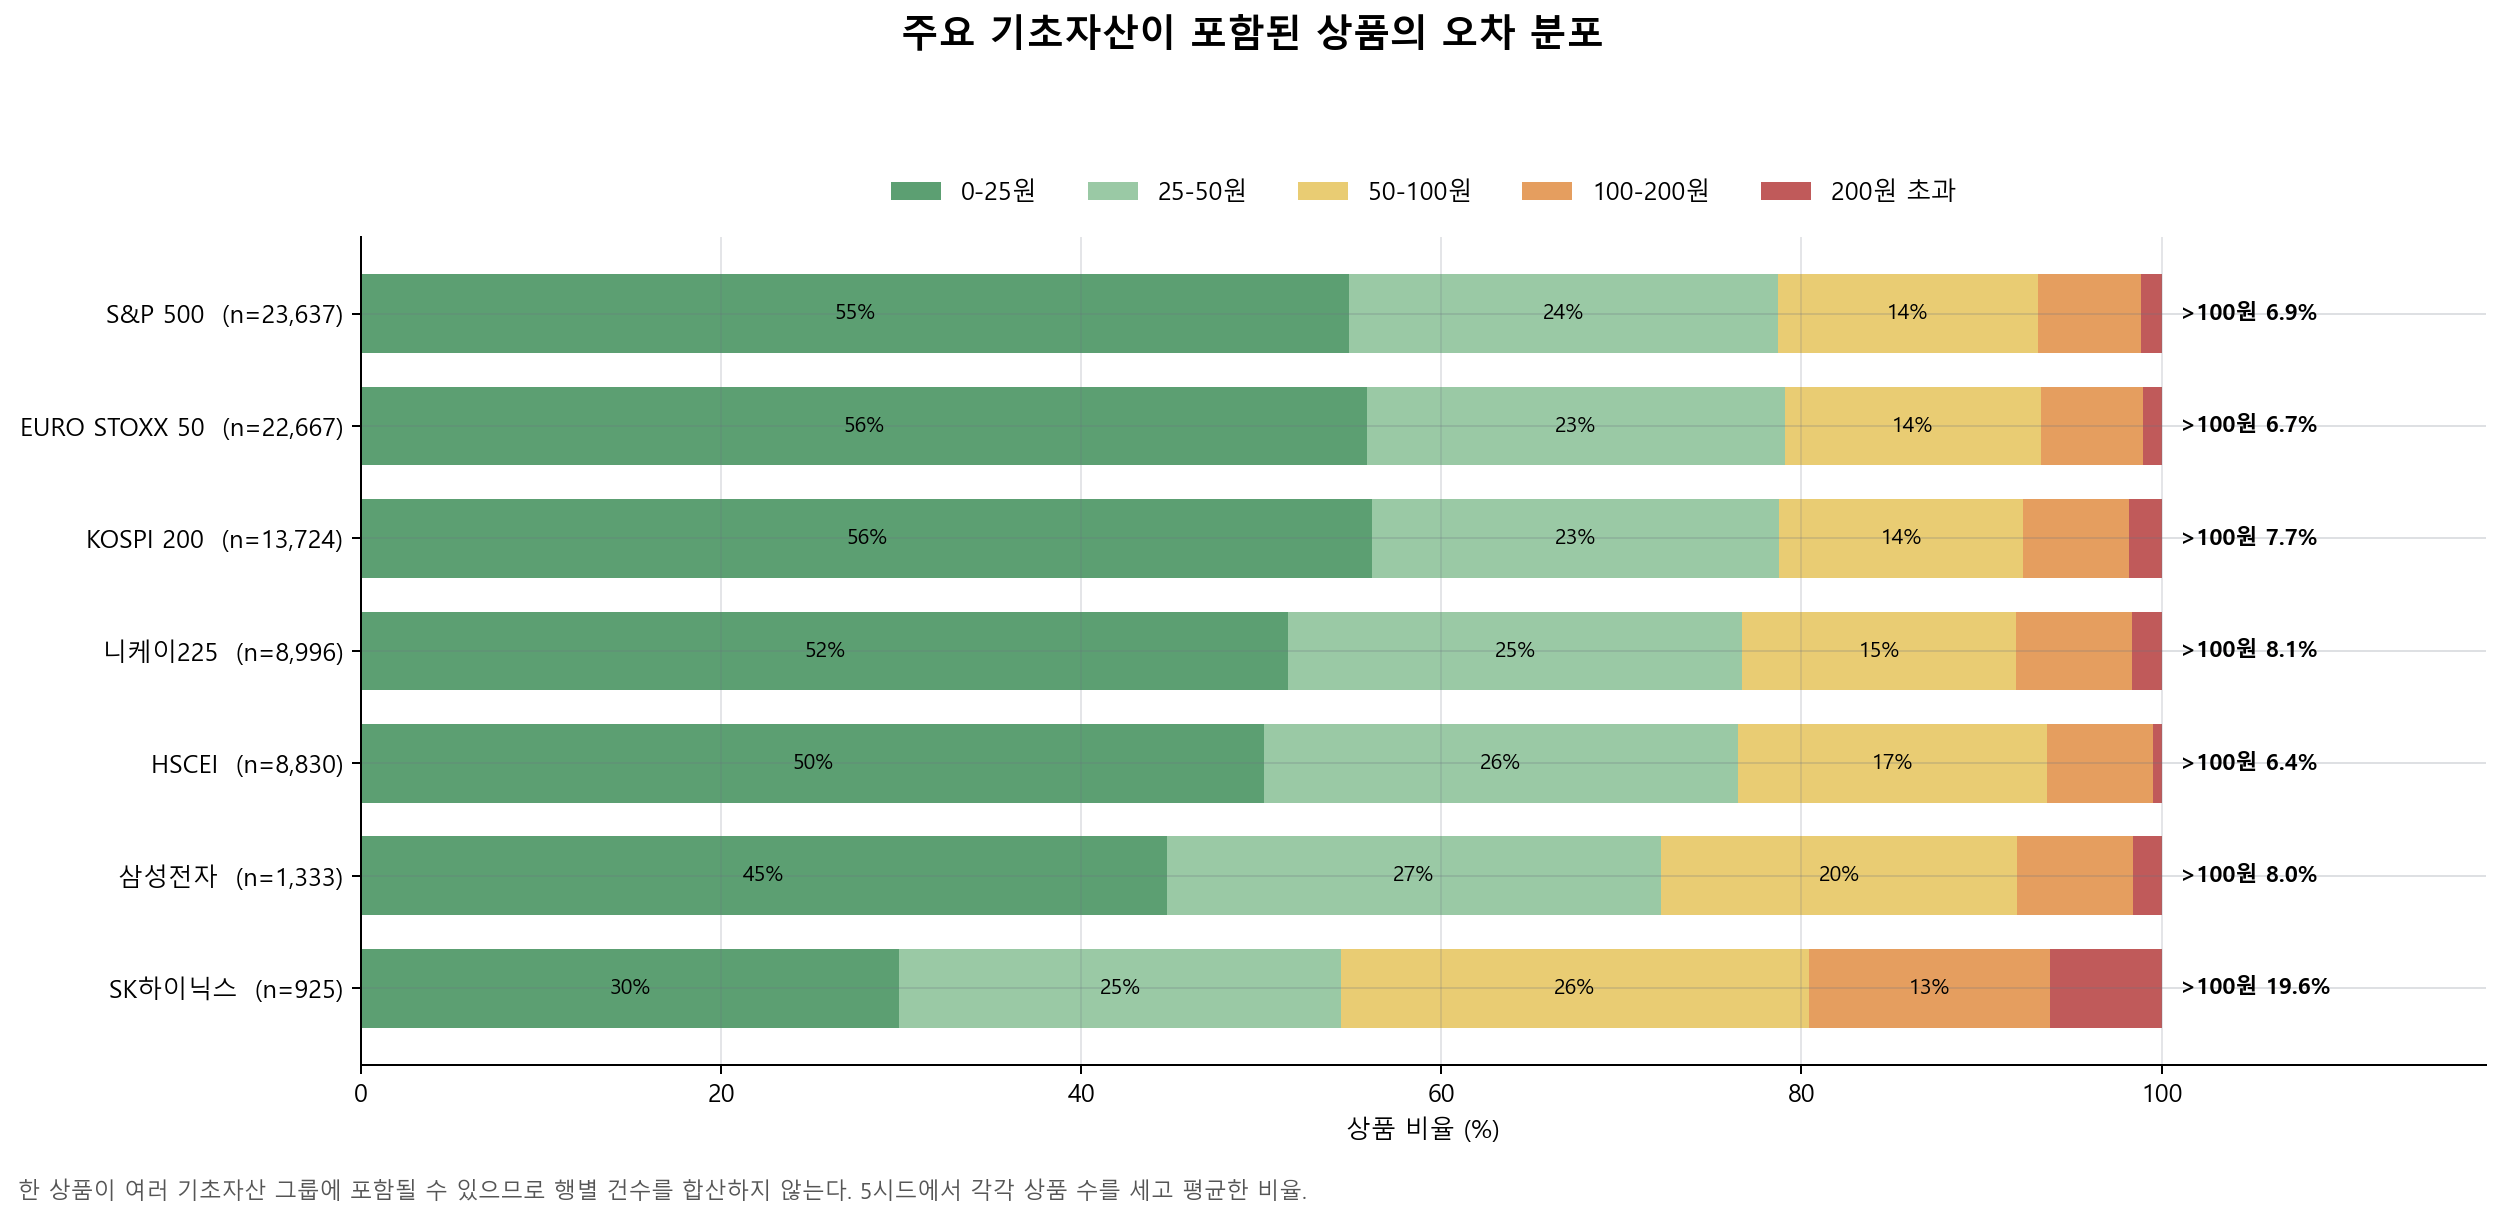